# Partie C — Cavité entraînée à $Re = 10\,000 > Re_c$ : perte de stationnarité

Énoncé, Partie C : au-delà de $Re_c$ (proche de 8000 dans la littérature), la solution stationnaire devient instable et l'écoulement devient périodique.
- simuler l'écoulement au $Re$ le plus élevé possible, en le justifiant ;
- étudier la sensibilité des résultats à ce $Re$ aux choix numériques ;
- comparer à la littérature ou à un autre solveur validé.

**Choix de l'équipe** (PLAN.md, étape 5) : $Re = 10\,000$, M1 (projection) et M2 ($\psi$–$\omega$), Euler explicite, départ du repos (même condition
initiale qu'en Parties A et B), gradient conjugué (tol $10^{-8}$), $\Delta t$ = limites de stabilité du cours. Pas d'arrêt sur le résidu : calcul jusqu'à
$t = 300$ (cas 7 et 8 : $t = 1000$ ; cas 9 et 10 : $t = 2000$). Calculs faits avec `scripts/partie_C.py` (lancés par `scripts/lancer_partie_C.sh`, un processus par cas) et relus ici.

| Cas | Méthode | Advection | $\Delta t$ | $N$ | Rôle |
| --- | --- | --- | --- | --- | --- |
| 0 | M2 | centrée | $\Delta t/2$ | 128 | erreur d'Euler sur période et amplitude |
| 1, 2 | M1, M2 | centrée | $\Delta t$ | 128 | calculs principaux (grille de Ghia à $Re \le 3200$) |
| 3, 4 | M1, M2 | upwind | $\Delta t$ | 128 | choix « malheureux » (diffusion numérique) |
| 5, 6 | M2, M1 | centrée | $\Delta t$ | 256 | sensibilité au maillage (grille de Ghia à $Re = 10\,000$) |
| 7, 8 | M1, M2 | centrée | $\Delta t$ | 128 | cas 1, 2 prolongés jusqu'à $t = 1000$ : l'oscillation s'éteint-elle ou s'entretient-elle ? |
| 9, 10 | M2, M1 | centrée | $\Delta t$ | 128 | jusqu'à $t = 2000$ : régime final (stationnaire ou périodique) |

Plan : 1. budget ; 2. $K(t)$, $P(t)$, résidu ; 3. période et amplitude ; 4. oscillation physique ou numérique ; 5. un cycle ; 6. sensibilité ;
7. comparaison à la littérature ; 8. bilan.

In [1]:
import os
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"   # défaut de l'environnement CFD sur une des machines (cf. notebook A), avant numpy
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, REF = ROOT / "figures", ROOT / "ref_data"
FIG.mkdir(exist_ok=True)

# Mêmes cas, mêmes noms de fichiers que le script de calcul (une seule source de vérité)
from scripts.partie_C import CASES, PROBES, RE, T_MAX, case_dt, run_path

NU = 1.0 / RE
COLORS = plt.get_cmap("tab20").colors[::2] + plt.get_cmap("tab20").colors[1::2]   # 20 couleurs : une par cas


def color_of(k):
    return COLORS[k % len(COLORS)]

LABEL = {"centered": "centré", "upwind": "upwind"}


def case_name(k):
    method, scheme, factor, n, t_max = CASES[k]
    return (f"{method} {LABEL[scheme]}" + ("" if factor == 1 else f" Δt×{factor:g}") + f", N = {n}"
            + ("" if t_max == T_MAX else f", t ≤ {t_max:g}"))


# np.load ne lit un tableau qu'au moment où on y accède : les instantanés (lourds) ne sont lus que si on s'en sert
runs = {}
for k, case in enumerate(CASES):
    path = run_path(*case)
    if path.exists():
        runs[k] = np.load(path)
    else:
        print(f"cas {k} ({case_name(k)}) : pas encore de résultat ({path.name})")
print("cas disponibles :", sorted(runs))

cas disponibles : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 1. Budget : pourquoi $Re = 10\,000$ et $N = 128$

**Ce qu'on fait.** Pour chaque cas : $\Delta t$, nombre de pas, temps de calcul réel, coût d'un pas et nombre moyen d'itérations du gradient conjugué.

**Ce qu'on attend.** Avec l'advection centrée, $\Delta t \le 2\nu = 2 \cdot 10^{-4}$ (stabilité de l'advection-diffusion, cours §5.3.1.4) : $\Delta t$ ne dépend
pas de $N$, et il faut $\approx 1.9 \cdot 10^6$ pas pour $t = 300$. Le coût d'un pas croît comme le nombre de nœuds ($\times 4$ de $N = 128$ à $256$) fois le
nombre d'itérations du gradient conjugué (qui croît aussi avec $N$). L'upwind autorise $\Delta t \le h/2$ (CFL), soit 20 fois moins de pas.

In [2]:
print(f"{'cas':<26} | {'Δt':>8} | {'pas':>9} | {'calcul (h)':>10} | {'ms/pas':>6} | {'it. GC moy.':>11} | {'it. GC fin':>10}")
for k, r in runs.items():
    n_steps, wall = int(r["n_steps"]), float(r["wall_time"])
    it = r["cg_iterations"]
    print(f"{case_name(k):<26} | {float(r['dt']):8.2e} | {n_steps:9d} | {wall / 3600:10.2f} | {1e3 * wall / n_steps:6.2f} | "
          f"{it.mean():11.0f} | {it[-10000:].mean():10.0f}")
if runs:
    print("\nmachine :", str(next(iter(runs.values()))["machine"]))

cas                        |       Δt |       pas | calcul (h) | ms/pas | it. GC moy. | it. GC fin
M2 centré Δt×0.5, N = 128  | 8.00e-05 |   3750000 |       7.83 |   7.51 |         166 |        114
M1 centré, N = 128         | 1.60e-04 |   1875001 |       1.80 |   3.45 |          42 |         21
M2 centré, N = 128         | 1.60e-04 |   1875001 |       4.42 |   8.49 |         186 |        130
M1 upwind, N = 128         | 3.13e-03 |     96000 |       0.17 |   6.32 |          90 |         15
M2 upwind, N = 128         | 3.13e-03 |     96000 |       0.21 |   7.78 |         168 |         69
M2 centré, N = 256         | 1.60e-04 |   1875001 |      38.02 |  73.00 |         440 |        336
M1 centré, N = 256         | 1.60e-04 |   1875001 |      19.18 |  36.82 |         139 |        127
M1 centré, N = 128, t ≤ 1000 | 1.60e-04 |   6250000 |       2.86 |   1.65 |          19 |          9
M2 centré, N = 128, t ≤ 1000 | 1.60e-04 |   6250000 |       6.57 |   3.78 |          83 |          3
M2 cen

**Lecture** (tous les cas terminés ; Apple M1, un cœur par cas).
- Advection centrée : $\Delta t = 0.8 \times 2\nu = 1.6 \cdot 10^{-4}$, $1.9 \cdot 10^6$ pas pour $t = 300$ ; **1.8 h pour M1, 4.4 h pour M2** à $N = 128$. M2 est plus cher
  car son Poisson (sur $\psi$) demande ~4 fois plus d'itérations du gradient conjugué (186 contre 42 en moyenne).
- M2 avec $\Delta t/2$ (cas 0) : 2 fois plus de pas, **7.8 h** ; un pas coûte un peu moins (166 itérations au lieu de 186 : le départ du gradient conjugué,
  la solution du pas précédent, est plus proche de la solution).
- Upwind : 20 fois moins de pas, 10 à 13 min.
- $N = 256$ : M1 (cas 6) a demandé **19.2 h** (36.8 ms/pas, 11 fois plus qu'à $N = 128$ : 4 fois plus de nœuds et ~3 fois plus d'itérations du gradient
  conjugué, 139 contre 42). M2 (cas 5) : **38.0 h** (73 ms/pas : 440 itérations
  du gradient conjugué en moyenne, 3 fois plus que M1). C'est la limite de ce que la machine permet avant le rendu.
- $t \le 1000$ (cas 7, 8) : $6.25 \cdot 10^6$ pas, **2.9 h (M1) et 6.6 h (M2)**. Un pas coûte deux fois moins qu'à $t \le 300$ (1.65 contre 3.45 ms pour M1,
  3.78 contre 8.49 ms pour M2) : quand l'écoulement ne change presque plus, la solution du pas précédent est presque la bonne et le gradient conjugué
  converge en quelques itérations (M2 : 3 en fin de calcul).
- $t \le 2000$ (cas 9, 10) : $1.25 \cdot 10^7$ pas, **6.8 h (M2) et 7.4 h (M1)**. M1 ralentit après $t = 1000$ : quand l'oscillation grandit, le gradient
  conjugué refait ~45 itérations par pas (contre ~10 vers $t = 1000$).
- **Pourquoi pas plus haut que $Re = 10\,000$** : la couche limite sous le couvercle a une épaisseur $\sim Re^{-1/2}$, il faudrait donc $N \propto Re^{1/2}$ ; et
  $\Delta t \le 2\nu \propto Re^{-1}$. Le coût d'un calcul croît au moins comme $Re \cdot N^2 \propto Re^2$ : $Re = 20\,000$ coûterait 4 fois plus, sur une grille
  ($N = 256$) qui prend déjà plusieurs jours.

## 2. $K(t)$, $P(t)$ et résidu stationnaire

**Ce qu'on fait.** Les deux diagnostics imposés et le résidu $\|R\| = \|(f^{n+1} - f^n)/\Delta t\|$ (sur $u, v$ pour M1, sur $\omega$ pour M2 ; ADR 0003),
pour tous les cas. Un point sur 50 est tracé.

**Ce qu'on attend.** Au-delà de $Re_c$ : après le transitoire (rampe du couvercle, mise en rotation), $K$ et $P$ oscillent autour d'une moyenne et $\|R\|$
reste à un niveau constant (il ne tend pas vers 0). Pour l'upwind : un état stationnaire, $\|R\|$ décroît sans fin.

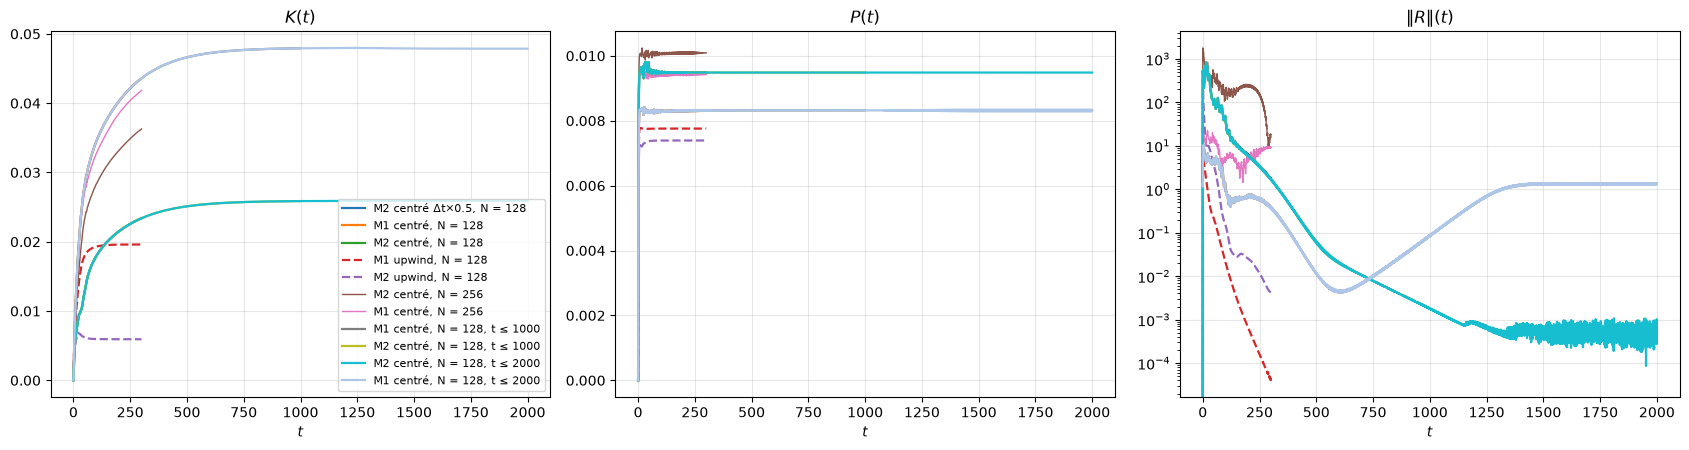

cas                        |    K(300) | dK/dt sur [250, 300] |    P(300) | ||R|| t=150 | ||R|| t=300
M2 centré Δt×0.5, N = 128  | 2.341e-02 |             1.63e-05 | 9.483e-03 |    1.02e+01 |    1.77e+00
M1 centré, N = 128         | 4.360e-02 |             2.90e-05 | 8.319e-03 |    5.96e-01 |    3.58e-01
M2 centré, N = 128         | 2.339e-02 |             1.64e-05 | 9.483e-03 |    9.59e+00 |    1.70e+00
M1 upwind, N = 128         | 1.960e-02 |             7.01e-08 | 7.757e-03 |    3.02e-03 |    4.01e-05
M2 upwind, N = 128         | 5.930e-03 |            -6.43e-09 | 7.390e-03 |    2.76e-02 |    4.19e-03
M2 centré, N = 256         | 3.628e-02 |             2.80e-05 | 1.009e-02 |    1.92e+02 |    1.84e+01
M1 centré, N = 256         | 4.183e-02 |             2.87e-05 | 9.450e-03 |    3.46e+00 |    9.29e+00


M1 centré, N = 128, t ≤ 1000 | 4.793e-02 |             4.92e-07 | 8.319e-03 |    5.96e-01 |    8.79e-02
M2 centré, N = 128, t ≤ 1000 | 2.587e-02 |             2.90e-07 | 9.483e-03 |    9.59e+00 |    1.79e-03
M2 centré, N = 128, t ≤ 2000 | 2.591e-02 |             7.95e-10 | 9.483e-03 |    9.59e+00 |    5.12e-04


M1 centré, N = 128, t ≤ 2000 | 4.786e-02 |            -1.36e-08 | 8.331e-03 |    5.96e-01 |    1.36e+00


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for k, r in runs.items():
    t, s = r["t"], slice(None, None, 50)
    ls = "-" if CASES[k][1] == "centered" else "--"
    lw = 1.6 if CASES[k][3] == 128 else 1.0
    for ax, key in zip(axes, ("K", "P", "residual")):
        ax.plot(t[s], r[key][s], ls=ls, lw=lw, color=color_of(k), label=case_name(k))
axes[2].set_yscale("log")
for ax, title in zip(axes, ("$K(t)$", "$P(t)$", r"$\|R\|(t)$")):
    ax.set_xlabel("$t$"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "C_K_P_residual.png", dpi=150)
plt.show()

print(f"{'cas':<26} | {'K(300)':>9} | {'dK/dt sur [250, 300]':>20} | {'P(300)':>9} | {'||R|| t=150':>11} | {'||R|| t=300':>11}")
for k, r in runs.items():
    t, K = r["t"], r["K"]
    m = t >= t[-1] - 50
    i150 = np.searchsorted(t, 150.0)
    print(f"{case_name(k):<26} | {K[-1]:9.3e} | {np.polyfit(t[m], K[m], 1)[0]:20.2e} | {r['P'][-1]:9.3e} | "
          f"{r['residual'][i150]:11.2e} | {r['residual'][-1]:11.2e}")

**Lecture.**
- **$P$ atteint un palier dès $t \approx 50$** : la couche limite sous le couvercle s'établit vite.
- **$K$ croît encore à $t = 300$** pour les deux calculs centrés : $+3.4\,\%$ (M1) et $+3.5\,\%$ (M2) sur les 50 dernières unités de temps. Le cœur du
  tourbillon principal se met en rotation très lentement. **À $t = 300$, l'écoulement moyen n'est pas établi** : $t_\text{max} = 300$ est trop court à
  $Re = 10\,000$ (en Partie B, il fallait déjà $t = 250$ à $430$ à $Re = 5000$).
- **$\Delta t/2$ (cas 0) ne change rien de visible** : sa courbe est cachée sous celle de M2 à $\Delta t$ ; $K(300) = 2.341 \cdot 10^{-2}$ contre $2.339 \cdot 10^{-2}$
  (0.1 %), $P(300)$ identique à 4 chiffres ($9.483 \cdot 10^{-3}$).
- Résidu : il reste vers $0.4$–$0.6$ pour M1 depuis $t \approx 120$ (oscillation) et décroît lentement pour M2. Upwind : $\|R\|$ décroît
  exponentiellement et $K$ ne varie plus, l'écoulement est stationnaire.
- $K$ diffère d'un facteur 2 entre M1 et M2 centrés (et 3.3 en upwind) alors que $P$ est proche : la différence est dans le cœur du tourbillon (§7).
- **Jusqu'à $t = 1000$ (cas 7, 8)** : $K$ croît encore de 10 % après $t = 300$ ($4.36 \to 4.79 \cdot 10^{-2}$ pour M1, $2.34 \to 2.59 \cdot 10^{-2}$ pour M2), mais
  $dK/dt$ sur $[950, 1000]$ est ~60 fois plus faible qu'à $t = 300$ ($4.9 \cdot 10^{-7}$ et $2.9 \cdot 10^{-7}$) : **l'écoulement moyen est presque établi vers
  $t = 1000$**. Le résidu de M2 tombe à $1.8 \cdot 10^{-3}$ (vers un état stationnaire), celui de M1 reste à $8.8 \cdot 10^{-2}$. Sur $[0, 300]$, les cas 7 et 8
  redonnent exactement les cas 1 et 2.
- **$N = 256$, M1 (cas 6)** : $K(300) = 4.18 \cdot 10^{-2}$, 4 % sous $N = 128$ ; $P(300) = 9.45 \cdot 10^{-3}$ contre $8.32 \cdot 10^{-3}$, $P$ croît avec $N$ comme prévu
  (singularité des coins du couvercle, croissance en $\ln N$, PLAN.md §2). Résidu $9.3$, 25 fois celui de $N = 128$ : l'oscillation est beaucoup plus forte.
- **$N = 256$, M2 (cas 5)** : $K(300) = 3.63 \cdot 10^{-2}$, contre $4.18 \cdot 10^{-2}$ pour M1. **L'écart entre méthodes passe de 46 % à $N = 128$ à 13 % à
  $N = 256$** : il vient surtout du manque de résolution. $P(300) = 1.009 \cdot 10^{-2}$ (M1 : $0.945 \cdot 10^{-2}$, 7 % d'écart).
- **Jusqu'à $t = 2000$ (cas 9, 10)** : $K$ ne bouge plus ($dK/dt \approx 10^{-9}$ à $10^{-8}$ sur $[1950, 2000]$) : $K = 2.59 \cdot 10^{-2}$ (M2), $4.79 \cdot 10^{-2}$ (M1).
  Le résidu de M2 se stabilise vers $5 \cdot 10^{-4}$ (plancher fixé par la tolérance du gradient conjugué) ; celui de M1 remonte à $1.4$ : il oscille.


## 3. Période et amplitude des oscillations

**Ce qu'on fait** (méthode simple, sans transformée de Fourier). Sur les 50 dernières unités de temps d'un signal $s(t)$ (une sonde, ou $K$) :
1. on retire la tendance lente par une parabole de moindres carrés ($K$ dérive encore lentement, §2 ; une droite ne suffit pas : sa courbure
   laisse un lobe sur deux au-dessus de zéro) ;
2. on découpe le signal en « lobes » positifs (entre deux passages par zéro) et on garde **un seul maximum par lobe** (cela évite de compter les petits
   maxima secondaires d'un signal non sinusoïdal) ;
3. **période** = moyenne des écarts entre maxima successifs (écart-type = incertitude) ; **amplitude** d'un cycle = (max − min)/2 sur ce cycle ;
4. **taux de croissance** $\sigma$ : pente de $\ln(\text{amplitude})$ en fonction du temps. $\sigma \approx 0$ : oscillation entretenue (régime périodique établi) ;
   $\sigma < 0$ : oscillation amortie (l'écoulement tend vers un état stationnaire) ; $\sigma > 0$ : oscillation qui croît encore.

Un signal dont la variation relative est inférieure à $10^{-5}$ est déclaré stationnaire (au-dessous, on ne mesure que le bruit d'arrondi et du
gradient conjugué).

Sondes : $u$ en 6 points fixes (`scripts/partie_C.py`) : à 2 mailles ($N = 128$) des coins du couvercle, au centre, près des trois autres coins.

**Ce qu'on attend.** Une période de l'ordre de quelques unités de temps $L/U$, la même pour toutes les sondes et pour $K$ (un seul mode global).

In [4]:
def oscillation(t, s, window=50.0):
    # Période, amplitude et taux de croissance d'un signal sur [t_fin - window, t_fin] (méthode décrite ci-dessus)
    m = t >= t[-1] - window
    tt, ss = t[m], s[m]
    ss = ss - np.polyval(np.polyfit(tt, ss, 2), tt)            # 1. tendance lente (parabole) retirée
    scale = np.abs(s[m]).mean() + 1e-300
    if np.ptp(ss) < 1e-5 * scale:                                # variation < 10⁻⁵ en relatif (bruit d'arrondi) : stationnaire
        return {"period": np.nan, "period_std": np.nan, "amplitude": 0.0, "sigma": np.nan, "n_cycles": 0, "rel_amp": 0.0}
    pos = ss > 0
    starts = np.where(~pos[:-1] & pos[1:])[0] + 1                # passages par zéro vers le haut : début d'un lobe positif
    t_max, amps = [], []
    for a, b in zip(starts[:-1], starts[1:]):                    # un cycle = d'un début de lobe au suivant
        seg = ss[a:b]
        t_max.append(tt[a + np.argmax(seg)])                     # 2. un seul maximum par cycle
        amps.append(0.5 * (seg.max() - seg.min()))               # 3. amplitude du cycle
    t_max, amps = np.array(t_max), np.array(amps)
    if len(t_max) < 3:
        return {"period": np.nan, "period_std": np.nan, "amplitude": np.ptp(ss) / 2, "sigma": np.nan,
                "n_cycles": len(t_max), "rel_amp": np.ptp(ss) / 2 / scale}
    periods = np.diff(t_max)
    sigma = np.polyfit(t_max, np.log(amps), 1)[0]                # 4. ln(amplitude) ≈ σ t + cste
    return {"period": periods.mean(), "period_std": periods.std(), "amplitude": amps[-3:].mean(), "sigma": sigma,
            "n_cycles": len(t_max), "rel_amp": amps[-3:].mean() / scale}


def regime(osc):
    # Classement à partir du taux de croissance (seuil : amplitude divisée ou multipliée par e en plus de 1000 unités de temps)
    if osc["n_cycles"] < 3:
        return "stationnaire / pas d'oscillation"
    if abs(osc["sigma"]) < 1e-3:
        return "périodique établi"
    return "amortie" if osc["sigma"] < 0 else "croissante"


print(f"{'cas':<26} {'signal':<22} | {'période':>15} | {'amplitude':>9} | {'ampl. rel.':>10} | {'σ':>9} | régime")
for k, r in runs.items():
    signals = {"K": r["K"]} | {name: r["probe_u"][:, j] for j, name in enumerate(r["probe_names"])}
    for name, s in signals.items():
        o = oscillation(r["t"], s)
        print(f"{case_name(k):<26} {name:<22} | {o['period']:7.3f} ± {o['period_std']:5.3f} | {o['amplitude']:9.2e} | "
              f"{o['rel_amp']:10.1e} | {o['sigma']:9.2e} | {regime(o)}")
    print()

cas                        signal                 |         période | amplitude | ampl. rel. |         σ | régime


M2 centré Δt×0.5, N = 128  K                      |   4.972 ± 0.007 |  7.92e-07 |    3.4e-05 | -1.52e-02 | amortie
M2 centré Δt×0.5, N = 128  coin_couvercle_gauche  |   4.970 ± 0.023 |  8.81e-05 |    6.0e-03 | -1.32e-02 | amortie
M2 centré Δt×0.5, N = 128  coin_couvercle_droit   |   4.970 ± 0.023 |  5.39e-05 |    2.3e-04 | -1.36e-02 | amortie
M2 centré Δt×0.5, N = 128  centre                 |   4.962 ± 0.032 |  8.74e-05 |    5.9e-03 | -1.14e-02 | amortie
M2 centré Δt×0.5, N = 128  bas_gauche             |   4.970 ± 0.023 |  4.47e-04 |    1.9e-02 | -1.47e-02 | amortie
M2 centré Δt×0.5, N = 128  bas_droit              |   4.967 ± 0.028 |  1.00e-04 |    3.0e-01 | -1.53e-02 | amortie


M2 centré Δt×0.5, N = 128  haut_gauche            |   4.975 ± 0.026 |  8.99e-05 |    2.0e-03 | -1.49e-02 | amortie

M1 centré, N = 128         K                      |   3.642 ± 0.016 |  4.09e-06 |    9.5e-05 | -1.10e-02 | amortie
M1 centré, N = 128         coin_couvercle_gauche  |   3.643 ± 0.015 |  7.64e-03 |    2.2e-02 | -8.93e-03 | amortie


M1 centré, N = 128         coin_couvercle_droit   |   3.642 ± 0.021 |  4.20e-04 |    1.8e-03 | -8.24e-03 | amortie
M1 centré, N = 128         centre                 |   3.636 ± 0.017 |  4.81e-04 |    2.6e-02 | -6.48e-03 | amortie
M1 centré, N = 128         bas_gauche             |   3.637 ± 0.024 |  1.73e-03 |    9.3e-02 | -1.10e-02 | amortie
M1 centré, N = 128         bas_droit              |   3.641 ± 0.035 |  5.60e-04 |    5.6e-02 | -1.22e-02 | amortie
M1 centré, N = 128         haut_gauche            |   3.635 ± 0.050 |  1.77e-03 |    2.3e-02 | -1.08e-02 | amortie



M2 centré, N = 128         K                      |   4.974 ± 0.007 |  7.67e-07 |    3.3e-05 | -1.52e-02 | amortie
M2 centré, N = 128         coin_couvercle_gauche  |   4.971 ± 0.023 |  8.55e-05 |    5.8e-03 | -1.31e-02 | amortie
M2 centré, N = 128         coin_couvercle_droit   |   4.971 ± 0.023 |  5.24e-05 |    2.2e-04 | -1.34e-02 | amortie
M2 centré, N = 128         centre                 |   4.962 ± 0.032 |  8.51e-05 |    5.8e-03 | -1.12e-02 | amortie
M2 centré, N = 128         bas_gauche             |   4.971 ± 0.024 |  4.35e-04 |    1.9e-02 | -1.45e-02 | amortie
M2 centré, N = 128         bas_droit              |   4.969 ± 0.028 |  9.75e-05 |    2.9e-01 | -1.53e-02 | amortie
M2 centré, N = 128         haut_gauche            |   4.976 ± 0.027 |  8.75e-05 |    1.9e-03 | -1.47e-02 | amortie

M1 upwind, N = 128         K                      |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M1 upwind, N = 128         coin_couvercle_gauche  |   

M2 centré, N = 256         K                      |   2.353 ± 0.671 |  1.77e-06 |    5.0e-05 | -4.44e-02 | amortie
M2 centré, N = 256         coin_couvercle_gauche  |   2.217 ± 0.496 |  5.26e-04 |    1.2e-02 | -5.86e-02 | amortie
M2 centré, N = 256         coin_couvercle_droit   |   2.204 ± 0.513 |  1.08e-04 |    5.2e-04 | -6.45e-02 | amortie
M2 centré, N = 256         centre                 |   3.939 ± 0.089 |  9.93e-05 |    5.7e-03 | -6.34e-03 | amortie
M2 centré, N = 256         bas_gauche             |   2.318 ± 0.642 |  8.62e-04 |    3.2e-02 | -5.82e-02 | amortie
M2 centré, N = 256         bas_droit              |   2.582 ± 0.871 |  8.26e-05 |    9.9e-03 | -4.48e-02 | amortie
M2 centré, N = 256         haut_gauche            |   2.099 ± 0.319 |  6.39e-04 |    1.1e-02 | -7.45e-02 | amortie



... (3 outputs left out)

M2 centré, N = 128, t ≤ 2000 K                      |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M2 centré, N = 128, t ≤ 2000 coin_couvercle_gauche  |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M2 centré, N = 128, t ≤ 2000 coin_couvercle_droit   |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M2 centré, N = 128, t ≤ 2000 centre                 |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M2 centré, N = 128, t ≤ 2000 bas_gauche             |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation


M2 centré, N = 128, t ≤ 2000 bas_droit              |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation
M2 centré, N = 128, t ≤ 2000 haut_gauche            |     nan ±   nan |  0.00e+00 |    0.0e+00 |       nan | stationnaire / pas d'oscillation



M1 centré, N = 128, t ≤ 2000 K                      |   2.283 ± 0.000 |  2.93e-06 |    6.1e-05 |  1.77e-05 | périodique établi
M1 centré, N = 128, t ≤ 2000 coin_couvercle_gauche  |   2.283 ± 0.000 |  1.86e-02 |    5.3e-02 | -1.68e-05 | périodique établi
M1 centré, N = 128, t ≤ 2000 coin_couvercle_droit   |   2.283 ± 0.000 |  1.22e-03 |    5.2e-03 |  4.53e-05 | périodique établi
M1 centré, N = 128, t ≤ 2000 centre                 |   2.283 ± 0.000 |  6.86e-05 |    2.6e-03 | -4.59e-05 | périodique établi
M1 centré, N = 128, t ≤ 2000 bas_gauche             |   2.283 ± 0.000 |  5.82e-03 |    3.1e-01 |  4.13e-05 | périodique établi


M1 centré, N = 128, t ≤ 2000 bas_droit              |   2.283 ± 0.000 |  1.11e-03 |    1.8e-01 |  2.15e-05 | périodique établi
M1 centré, N = 128, t ≤ 2000 haut_gauche            |   2.283 ± 0.000 |  4.48e-03 |    5.9e-02 | -2.01e-05 | périodique établi



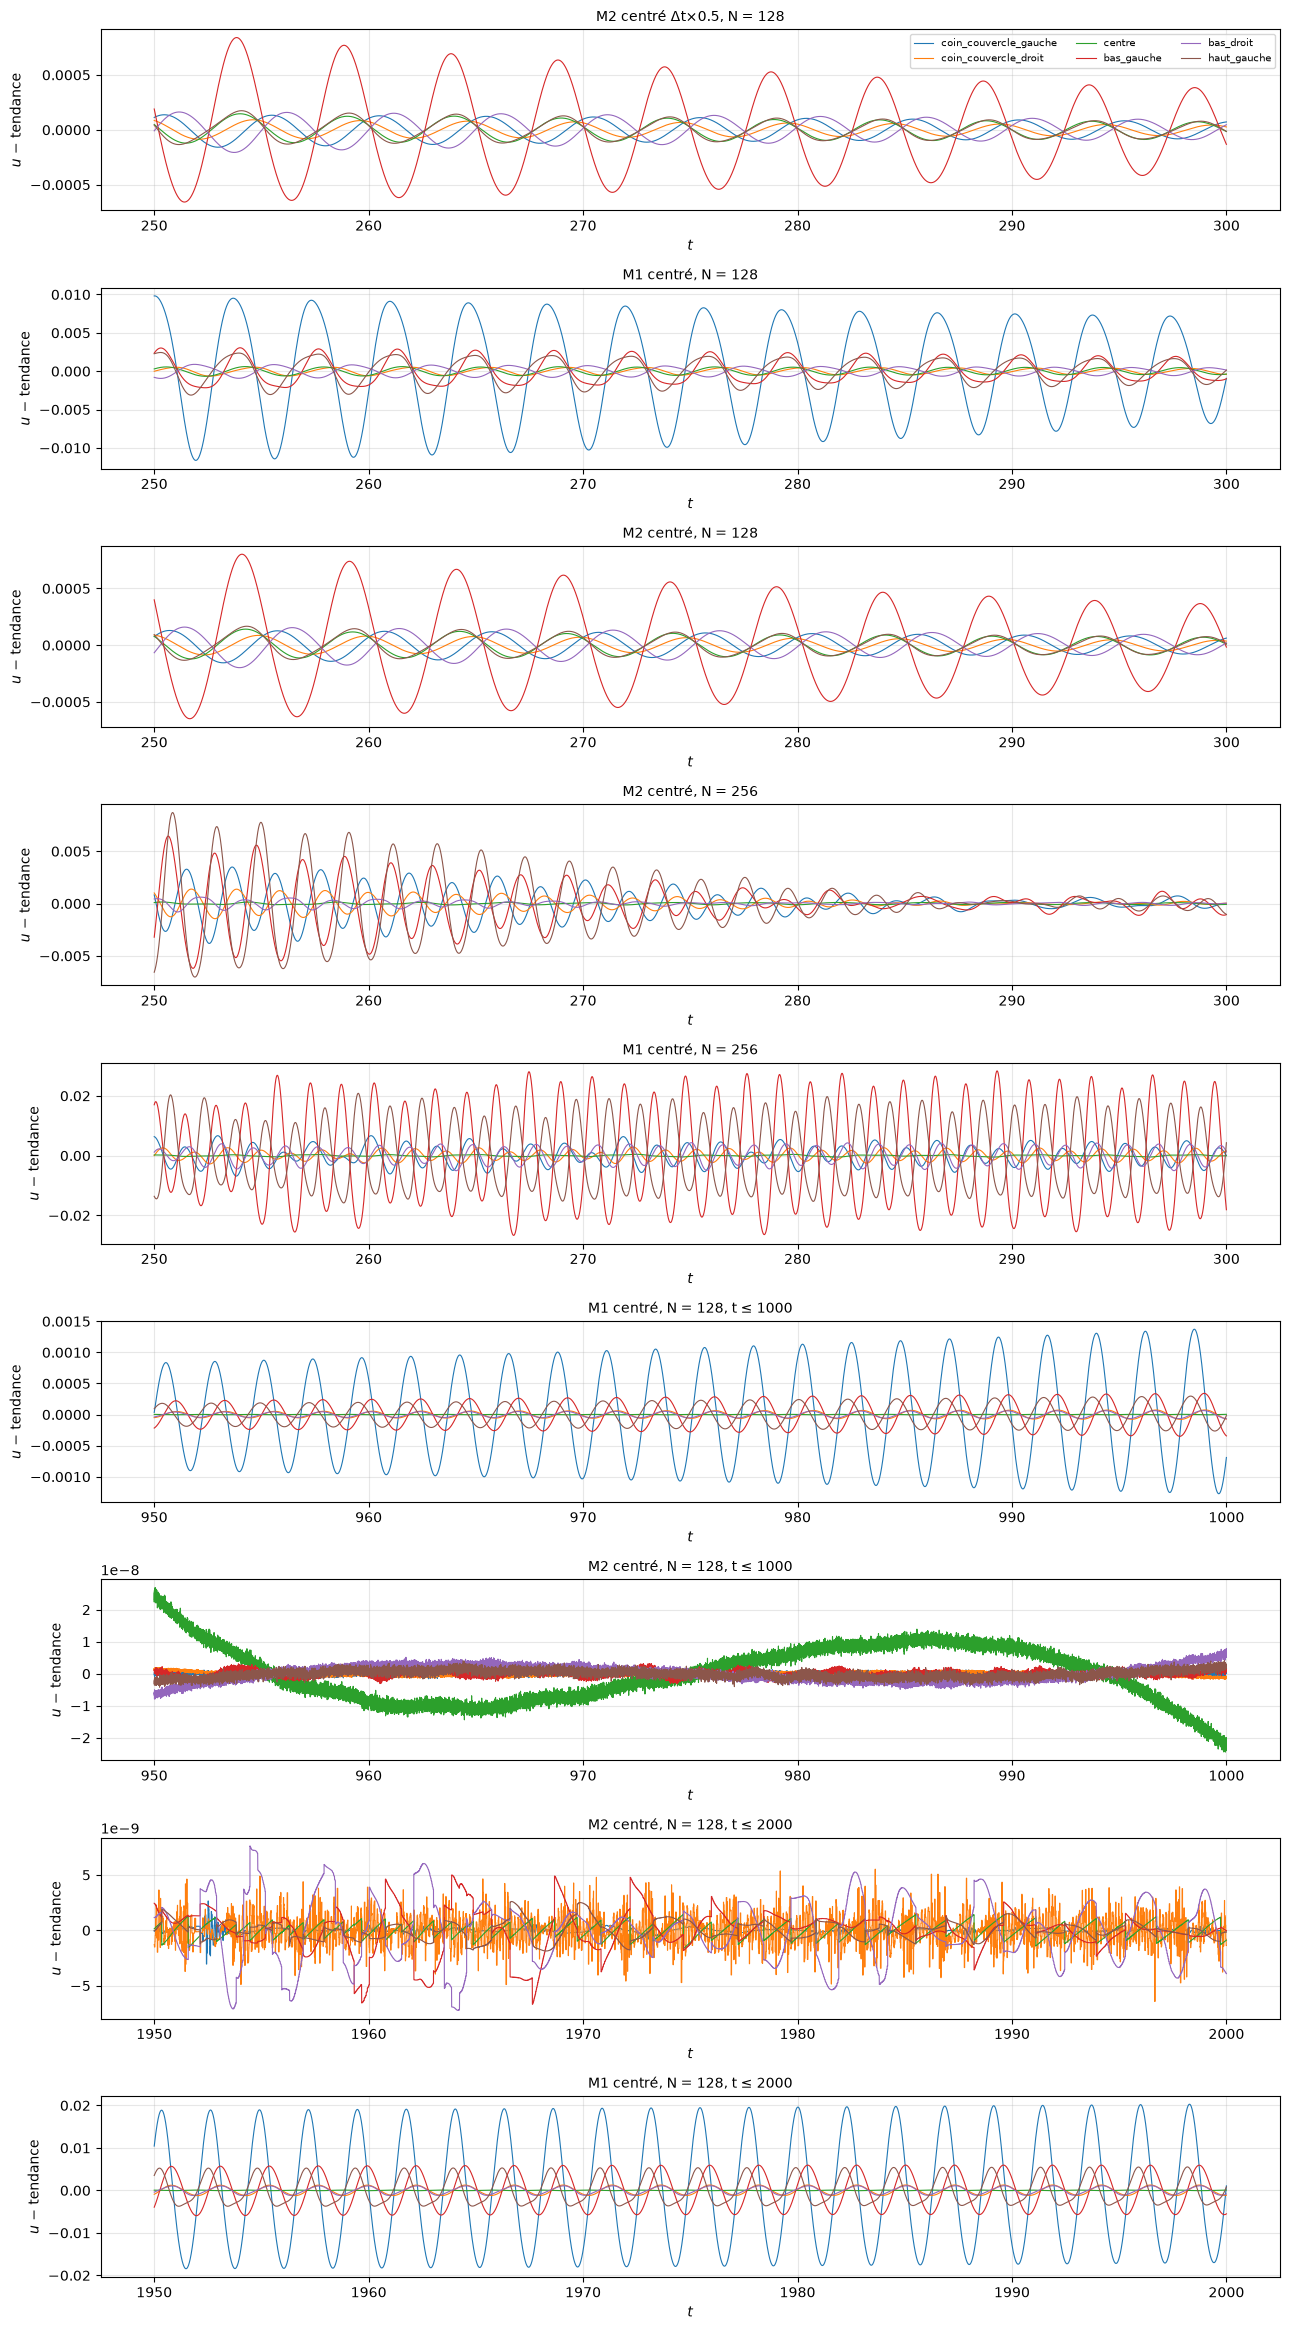

In [5]:
# Sondes sur les 50 dernières unités de temps, tendance retirée (un point sur 10)
centered = [k for k in runs if CASES[k][1] == "centered"]
fig, axes = plt.subplots(len(centered), 1, figsize=(13, 2.6 * len(centered)), squeeze=False)
for ax, k in zip(axes[:, 0], centered):
    r = runs[k]; t = r["t"]; m = t >= t[-1] - 50
    for j, name in enumerate(r["probe_names"]):
        s = r["probe_u"][m, j]
        ax.plot(t[m][::10], (s - np.polyval(np.polyfit(t[m], s, 2), t[m]))[::10], lw=0.8, label=name)
    ax.set_title(case_name(k), fontsize=10); ax.set_ylabel("$u$ − tendance"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7, ncol=3)
for ax in axes[:, 0]:
    ax.set_xlabel("$t$")
fig.tight_layout()
fig.savefig(FIG / "C_probes.png", dpi=150)
plt.show()

**Lecture.**
- Dans chaque calcul centré, **toutes les sondes et $K$ oscillent avec la même période** : c'est un seul mode, global.
- **La période dépend de la méthode** : $T = 3.64 \pm 0.02$ pour M1, $4.97 \pm 0.02$ pour M2 (37 % d'écart). Certaines sondes de M2 ont deux bosses par
  cycle (harmonique de période $\approx 2.5$) ; la méthode « un maximum par lobe » retrouve bien la fondamentale.
- **La période ne dépend pas de $\Delta t$** : M2 à $\Delta t/2$ donne $T = 4.972 \pm 0.007$ sur $K$ contre $4.974 \pm 0.007$ à $\Delta t$ (écart 0.04 %, dans
  l'incertitude) ; même taux $\sigma = -1.52 \cdot 10^{-2}$ sur $K$ ; amplitudes à 3 % près ($7.92 \cdot 10^{-7}$ contre $7.67 \cdot 10^{-7}$ sur $K$). L'erreur
  d'Euler explicite est négligeable : **l'écart entre M1 et M2 ne vient pas du pas de temps**, mais de l'espace (grille, conditions aux parois).
- **À $N = 128$ et $t = 300$, les oscillations sont amorties** : $\sigma \approx -0.007$ à $-0.015$, l'amplitude est divisée par 2 en 50 à 100 unités de temps. À $t = 300$, aucun des
  deux calculs n'est donc dans un régime périodique établi. Mais comme l'écoulement moyen évolue encore (§2), on ne peut pas encore conclure qu'il
  tend vers un état stationnaire.
- Upwind : aucune oscillation mesurable (variation relative $< 10^{-5}$).
- Cas 6, 7, 8 : voir la cellule suivante (régime au cours du temps). **Limite de la méthode** : à partir de $t \approx 600$, la variation relative de
  $K$ du cas 7 passe sous le seuil de $10^{-5}$ alors que les sondes oscillent nettement ; $K$ est alors classé « stationnaire » à tort. Pour ces cas,
  le régime se lit sur les sondes.
- **M1 jusqu'à $t = 2000$ (cas 10) : régime périodique établi**, $T = 2.283$ sur $K$ et sur les six sondes, $\sigma \approx 10^{-5}$ (voir la cellule suivante).


In [6]:
# Régime au cours du temps : même mesure (fenêtre de 50 unités de temps) pour des fins de fenêtre successives
WINDOW_ENDS = {5: (200, 250, 300), 6: (200, 250, 300), 7: range(300, 1001, 100), 8: range(300, 1001, 100),
               9: (1000, 1500, 2000), 10: range(1000, 2001, 100)}
for k, ends in WINDOW_ENDS.items():
    if k not in runs:
        continue
    r = runs[k]
    t = r["t"]
    names = list(r["probe_names"])
    print(case_name(k))
    for t_end in ends:
        m = t <= t_end + 1e-9
        for name in ("coin_couvercle_gauche", "bas_gauche"):
            o = oscillation(t[m], r["probe_u"][m, names.index(name)])
            print(f"  [{t_end - 50:4d}, {t_end:4d}]  {name:<22} T = {o['period']:6.3f} ± {o['period_std']:5.3f} | amplitude {o['amplitude']:8.2e} | "
                  f"σ = {o['sigma']:9.2e} | {regime(o)}")
    print()


M2 centré, N = 256
  [ 150,  200]  coin_couvercle_gauche  T =  2.117 ± 0.080 | amplitude 4.76e-03 | σ =  3.64e-03 | croissante
  [ 150,  200]  bas_gauche             T =  2.129 ± 0.112 | amplitude 1.23e-02 | σ =  6.18e-03 | croissante
  [ 200,  250]  coin_couvercle_gauche  T =  2.080 ± 0.035 | amplitude 3.78e-03 | σ = -5.70e-03 | amortie
  [ 200,  250]  bas_gauche             T =  2.075 ± 0.058 | amplitude 7.15e-03 | σ = -1.30e-02 | amortie


  [ 250,  300]  coin_couvercle_gauche  T =  2.217 ± 0.496 | amplitude 5.26e-04 | σ = -5.86e-02 | amortie
  [ 250,  300]  bas_gauche             T =  2.318 ± 0.642 | amplitude 8.62e-04 | σ = -5.82e-02 | amortie

M1 centré, N = 256
  [ 150,  200]  coin_couvercle_gauche  T =  1.841 ± 0.352 | amplitude 6.80e-03 | σ =  3.94e-03 | croissante
  [ 150,  200]  bas_gauche             T =  1.803 ± 0.285 | amplitude 8.86e-03 | σ =  7.67e-03 | croissante
  [ 200,  250]  coin_couvercle_gauche  T =  1.707 ± 0.285 | amplitude 3.11e-03 | σ = -1.37e-02 | amortie


  [ 200,  250]  bas_gauche             T =  1.575 ± 0.218 | amplitude 2.17e-02 | σ =  9.74e-03 | croissante
  [ 250,  300]  coin_couvercle_gauche  T =  1.507 ± 0.241 | amplitude 4.09e-03 | σ = -1.16e-03 | amortie
  [ 250,  300]  bas_gauche             T =  1.456 ± 0.044 | amplitude 2.38e-02 | σ =  5.64e-03 | croissante

M1 centré, N = 128, t ≤ 1000


  [ 250,  300]  coin_couvercle_gauche  T =  3.643 ± 0.015 | amplitude 7.64e-03 | σ = -8.93e-03 | amortie
  [ 250,  300]  bas_gauche             T =  3.637 ± 0.024 | amplitude 1.73e-03 | σ = -1.10e-02 | amortie
  [ 350,  400]  coin_couvercle_gauche  T =  3.515 ± 0.017 | amplitude 1.42e-03 | σ = -1.86e-02 | amortie


  [ 350,  400]  bas_gauche             T =  3.511 ± 0.019 | amplitude 2.93e-04 | σ = -1.91e-02 | amortie
  [ 450,  500]  coin_couvercle_gauche  T =  3.444 ± 0.138 | amplitude 1.93e-04 | σ = -2.00e-02 | amortie
  [ 450,  500]  bas_gauche             T =  3.440 ± 0.121 | amplitude 3.78e-05 | σ = -2.05e-02 | amortie


  [ 550,  600]  coin_couvercle_gauche  T =  2.514 ± 0.614 | amplitude 4.93e-05 | σ = -5.07e-03 | amortie
  [ 550,  600]  bas_gauche             T =  2.399 ± 0.465 | amplitude 1.28e-05 | σ =  2.70e-03 | croissante


... (25 outputs left out)

  [1750, 1800]  bas_gauche             T =  2.283 ± 0.000 | amplitude 5.81e-03 | σ = -5.82e-05 | périodique établi


  [1850, 1900]  coin_couvercle_gauche  T =  2.283 ± 0.000 | amplitude 1.86e-02 | σ = -5.49e-05 | périodique établi


  [1850, 1900]  bas_gauche             T =  2.283 ± 0.000 | amplitude 5.81e-03 | σ = -1.51e-05 | périodique établi
  [1950, 2000]  coin_couvercle_gauche  T =  2.283 ± 0.000 | amplitude 1.86e-02 | σ = -1.68e-05 | périodique établi


  [1950, 2000]  bas_gauche             T =  2.283 ± 0.000 | amplitude 5.82e-03 | σ =  4.13e-05 | périodique établi



**Lecture.**
- **M2, $N = 128$ (cas 8) : l'oscillation s'éteint, l'écoulement devient stationnaire.** Sa période raccourcit pendant qu'elle s'amortit ($T = 4.97$, $4.81$,
  $4.70$ pour les fenêtres finissant à 300, 400, 500 ; $\sigma \approx -0.015$ à $-0.02$). Après $t \approx 600$, plus de période nette et des amplitudes de
  $10^{-6}$ ou moins (bruit d'arrondi et du gradient conjugué). Le gradient conjugué ne fait plus que 3 itérations par pas en fin de calcul (§1).
- **M1, $N = 128$ (cas 7) : la première oscillation s'éteint aussi** ($T = 3.64$, $3.51$, $3.44$, $\sigma \approx -0.01$ à $-0.02$), **mais une deuxième apparaît vers
  $t \approx 600$ et croît** : $T = 2.284$, la même aux deux sondes (et aux six, §3), $\sigma \approx +8.8 \cdot 10^{-3}$ à $t = 1000$ (amplitude doublée en
  $\ln 2/\sigma \approx 79$ unités de temps). Elle n'a pas encore saturé à $t = 1000$ : le régime final de M1 n'est pas connu.
- **M1, $N = 256$ (cas 6)** : à $t = 300$, oscillation plus rapide et, à la sonde bas gauche, 14 fois plus forte qu'à $N = 128$ ($T \approx 1.46$, amplitude
  $2.4 \cdot 10^{-2}$ ; au coin gauche du couvercle, elle est au contraire 2 fois plus faible). Sa période raccourcit encore d'une fenêtre à l'autre et $\sigma$ change de signe d'une sonde à l'autre : **régime non établi à $t = 300$**.
- **M2, $N = 256$ (cas 5)** : une oscillation de période $T \approx 2.1$ ($2.12$ et $2.08$, à $\pm 0.1$ près, pour les fenêtres finissant à 200 et 250, la même
  aux deux sondes) croît jusqu'à $t \approx 200$ puis s'amortit nettement : sur $[250, 300]$, $\sigma \approx -0.06$, amplitude divisée par 14 à la sonde bas gauche
  ($1.2 \cdot 10^{-2} \to 8.6 \cdot 10^{-4}$) et période moins nette. Comme M1 à $N = 256$, **régime non établi à $t = 300$** ; les deux méthodes ont des périodes du
  même ordre (1.5 à 2.1) mais pas égales.
- **M2 jusqu'à $t = 2000$ (cas 9)** : reste stationnaire de $t = 1000$ à $2000$ (aucune oscillation au-dessus du bruit d'arrondi). Sa figure des sondes
  (§3) ne montre que ce bruit, à l'échelle $10^{-10}$.
- **M1 jusqu'à $t = 2000$ (cas 10) : cycle limite.** L'oscillation de période 2.28 continue de croître jusqu'à $t \approx 1400$ ($\sigma$ passe de
  $8.8 \cdot 10^{-3}$ à $1.7 \cdot 10^{-3}$), puis son amplitude se stabilise : de $t = 1450$ à $2000$, $|\sigma| < 5 \cdot 10^{-4}$, amplitude constante ($1.87 \cdot 10^{-2}$ au
  coin gauche du couvercle, $5.8 \cdot 10^{-3}$ en bas à gauche), **$T = 2.283 \pm 0.001$**. C'est le comportement attendu après une bifurcation de
  Hopf (une instabilité qui croît puis sature) : **le seul régime périodique établi de nos calculs**.
- **À $N = 128$, M1 et M2 n'ont donc pas le même régime** (périodique établi contre stationnaire, confirmé jusqu'à $t = 2000$), avec les mêmes équations, le même maillage et
  le même $\Delta t$. Le régime dépend de la discrétisation en espace, dont les conditions aux parois (pression de Neumann par nœud fantôme pour M1,
  formule de Thom pour M2) : $N = 128$ ne suffit pas pour dire si l'écoulement à $Re = 10\,000$ est stationnaire ou périodique.


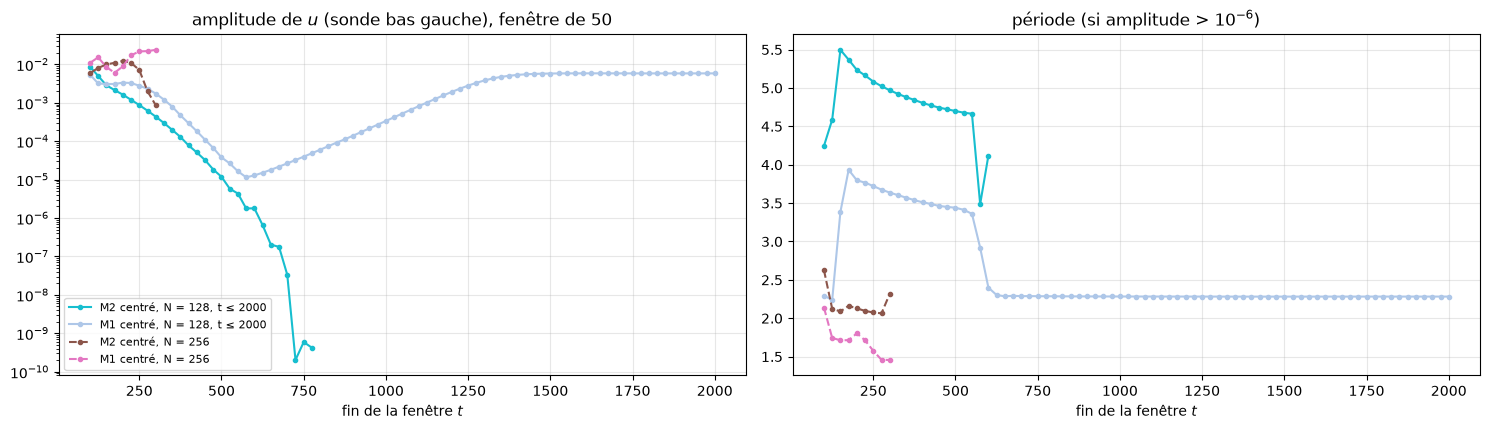

In [7]:
# Même mesure sur des fenêtres de 50 unités de temps glissées de 25 en 25 : amplitude et période au cours du temps (sonde bas gauche)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for k in (9, 10, 5, 6):
    if k not in runs:
        continue
    r = runs[k]
    t = r["t"]
    s = r["probe_u"][:, list(r["probe_names"]).index("bas_gauche")]
    ends = np.arange(100.0, float(r["t_final"]) + 1e-9, 25.0)
    oscs = [oscillation(t[t <= te + 1e-9], s[t <= te + 1e-9]) for te in ends]
    amp = np.array([o["amplitude"] for o in oscs])
    per = np.array([o["period"] if o["n_cycles"] >= 3 and o["amplitude"] > 1e-6 else np.nan for o in oscs])
    ls = "-" if CASES[k][3] == 128 else "--"
    axes[0].semilogy(ends, np.where(amp > 0, amp, np.nan), ls=ls, marker=".", color=color_of(k), label=case_name(k))
    axes[1].plot(ends, per, ls=ls, marker=".", color=color_of(k), label=case_name(k))
axes[0].set_title("amplitude de $u$ (sonde bas gauche), fenêtre de 50")
axes[1].set_title("période (si amplitude > $10^{-6}$)")
for ax in axes:
    ax.set_xlabel("fin de la fenêtre $t$"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "C_regime_evolution.png", dpi=150)
plt.show()


**Lecture de la figure.** À gauche, l'amplitude de l'oscillation au cours du temps (échelle log) ; à droite, sa période. Les cas 9 et 10
refont exactement les cas 1, 2, 7 et 8 sur leur durée. Une pente nulle de l'amplitude (palier) est un régime périodique établi ; une pente négative jusqu'au bruit d'arrondi, un retour à
l'état stationnaire.


## 4. Oscillation physique ou numérique ?

**Ce qu'on fait.** Deux contrôles (PLAN.md §2, « Singularités aux coins du couvercle ») :
- profils de $u$ sur les premières rangées sous le couvercle, près des deux coins, à $t = t_\text{fin}$ : des **zigzags nœud à nœud** signalent une
  oscillation numérique du schéma centré (Reynolds de maille $Uh/\nu = 78$ à $N = 128$, bien au-delà de 2, cours §5.4) ;
- carte de la variation de $u$ sur une unité de temps, $u(t_\text{fin}) - u(t_\text{fin} - 1)$ : où l'écoulement bouge-t-il ?

**Ce qu'on attend.** Une bifurcation de Hopf physique est un mode lisse, réparti sur la cavité (la littérature le place dans les tourbillons secondaires).
Une oscillation numérique est localisée aux coins du couvercle, sur 1 ou 2 mailles.

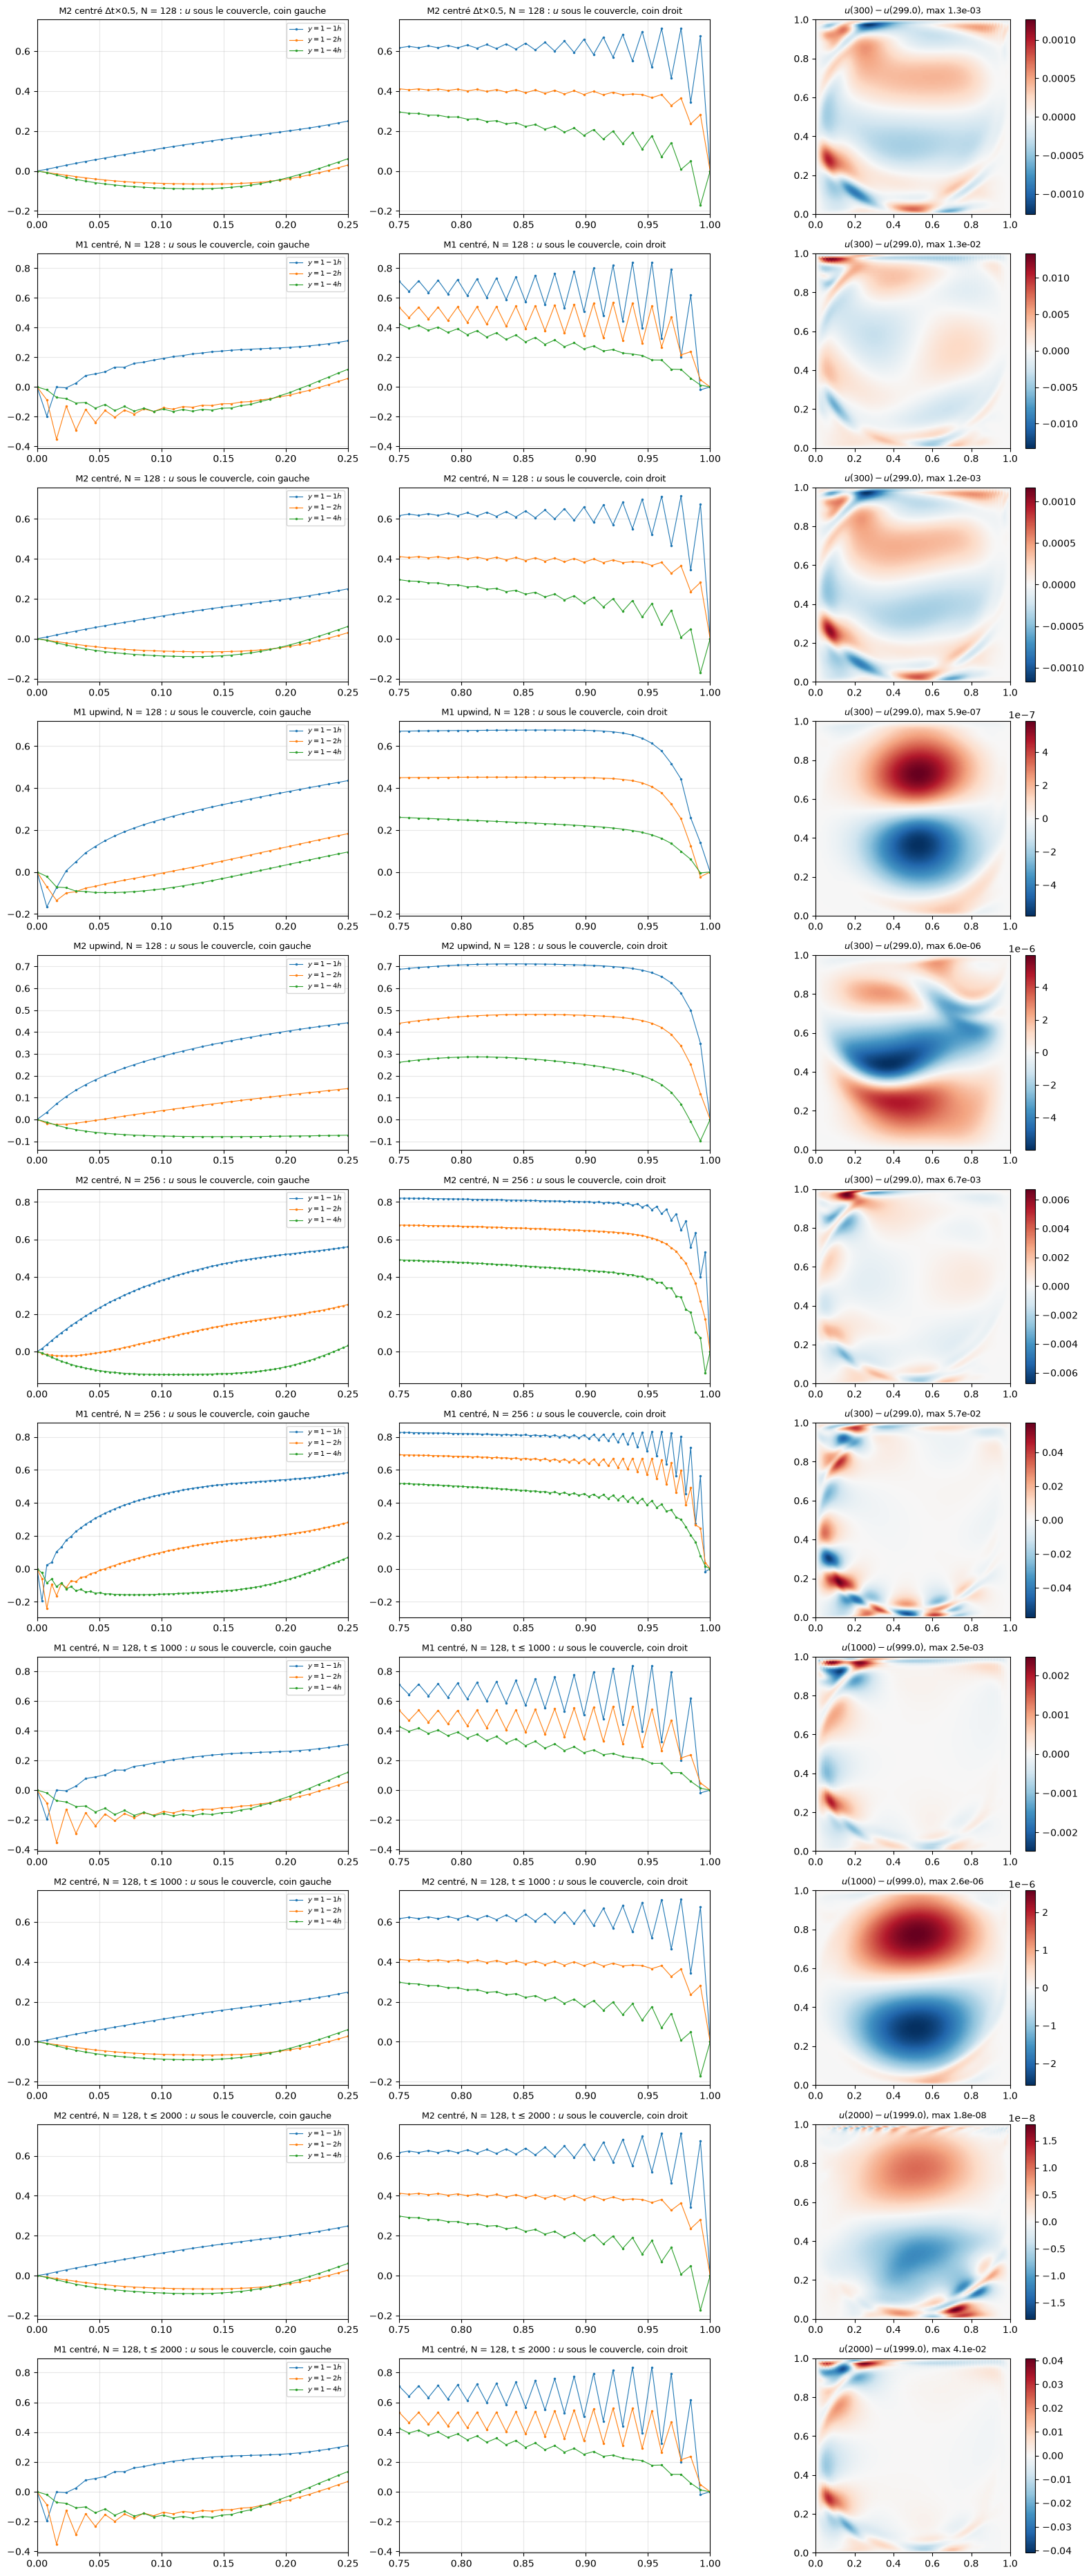

In [8]:
fig, axes = plt.subplots(len(runs), 3, figsize=(16, 3.4 * len(runs)), squeeze=False)
for row, (k, r) in enumerate(runs.items()):
    x, n = r["x"], int(r["N"])
    snap_u, snap_t = r["snap_u"], r["snap_t"]
    for col, (x0, x1, title) in enumerate(((0.0, 0.25, "coin gauche"), (0.75, 1.0, "coin droit"))):
        ax = axes[row, col]
        for d in (1, 2, 4):                                      # rangées j = N-1, N-2, N-4 sous le couvercle
            ax.plot(x, snap_u[-1][:, n - d], marker=".", ms=3, lw=0.8, label=f"$y = 1 - {d}h$")
        ax.set_xlim(x0, x1); ax.set_title(f"{case_name(k)} : $u$ sous le couvercle, {title}", fontsize=9); ax.grid(alpha=0.3)
    axes[row, 0].legend(fontsize=7)
    i_back = np.argmin(np.abs(snap_t - (snap_t[-1] - 1.0)))      # instantané une unité de temps plus tôt
    du = snap_u[-1] - snap_u[i_back]
    vmax = np.abs(du).max()
    im = axes[row, 2].imshow(du.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[row, 2].set_title(f"$u({snap_t[-1]:.0f}) - u({snap_t[i_back]:.1f})$, max {vmax:.1e}", fontsize=9)
    fig.colorbar(im, ax=axes[row, 2])
fig.tight_layout()
fig.savefig(FIG / "C_lid_rows_du.png", dpi=150)
plt.show()

**Lecture.**
- **Zigzags nœud à nœud** sous le couvercle, près du coin **droit** (là où l'écoulement du couvercle bute sur la paroi), pour **M1 et M2 centrés** : jusqu'à
  $\pm 0.2$ sur $u$ sur la première rangée ; M1 en a aussi près du coin gauche. C'est l'oscillation du schéma centré quand le Reynolds de maille
  dépasse 2 (ici 78) : **à $N = 128$, la couche limite du couvercle n'est pas résolue pour le schéma centré à $Re = 10\,000$**. Les profils upwind sont lisses.
- **Les zigzags de M2 sont les mêmes à $\Delta t/2$** (cas 0, première ligne) : ils viennent de la discrétisation en espace, pas du pas de temps.
- La variation de $u$ sur une unité de temps n'est pas limitée aux coins : elle couvre la couche de cisaillement qui entoure le tourbillon principal et les
  tourbillons secondaires. L'oscillation est donc un mode global, mais elle coexiste avec des zigzags numériques : à $N = 128$, on ne peut pas dire
  quelle part est physique. Le calcul à $N = 256$ (cas 5, 6) sert à trancher.
- **$N = 256$ (cas 6)** : les zigzags restent près du coin droit, mais sur une zone plus étroite ($x \gtrsim 0.87$ au lieu de toute la plage $0.75$–$1$) ;
  le Reynolds de maille vaut encore 39, au-delà de 2 : ils diminuent sans disparaître. La variation de $u$ sur une unité de temps
  ($5.7 \cdot 10^{-2}$ au plus) est le long des parois gauche et du bas et au coin haut gauche, pas au coin droit où sont les zigzags.
- **$t = 1000$ (cas 7, 8)** : zigzags toujours présents pour les deux méthodes, **y compris pour M2 devenu stationnaire** : ils sont une erreur de la grille,
  pas la cause de l'oscillation. Pour M1, la variation sur une unité de temps ($2.5 \cdot 10^{-3}$) est aux mêmes endroits qu'à $N = 256$ ; pour M2
  ($2.6 \cdot 10^{-6}$) c'est une seule grande structure lisse au cœur : la lente mise en rotation du tourbillon, pas une oscillation.
- **M2, $N = 256$ (cas 5)** : zigzags bien plus faibles qu'à $N = 128$, seulement sur la première rangée et pour $x \gtrsim 0.93$ ; profils lisses au coin gauche.
  La variation sur une unité de temps ($6.7 \cdot 10^{-3}$) est aux mêmes endroits que pour M1 : parois gauche et du bas, coin haut gauche.
- **M1, $t = 2000$ (cas 10)** : mêmes zigzags qu'à $t = 1000$ ; la variation sur une unité de temps ($4.1 \cdot 10^{-2}$) est à la paroi gauche et au coin
  haut gauche, loin des zigzags du coin droit.


## 5. Champs : vorticité moyenne et un cycle

**Ce qu'on fait.** Vorticité $\omega = \partial_x v - \partial_y u$ (stockée par M2 ; calculée par différences centrées pour M1), moyennée sur les instantanés
des 20 dernières unités de temps, puis sa **fluctuation** $\omega - \bar\omega$ à 4 instants espacés d'un quart de période. Échelle de couleur bornée :
$\omega$ a des pics en $1/h$ aux coins du couvercle, qui écraseraient tout le reste.

**Ce qu'on attend.** Une fluctuation organisée (un mode qui se déplace) si l'oscillation est physique.

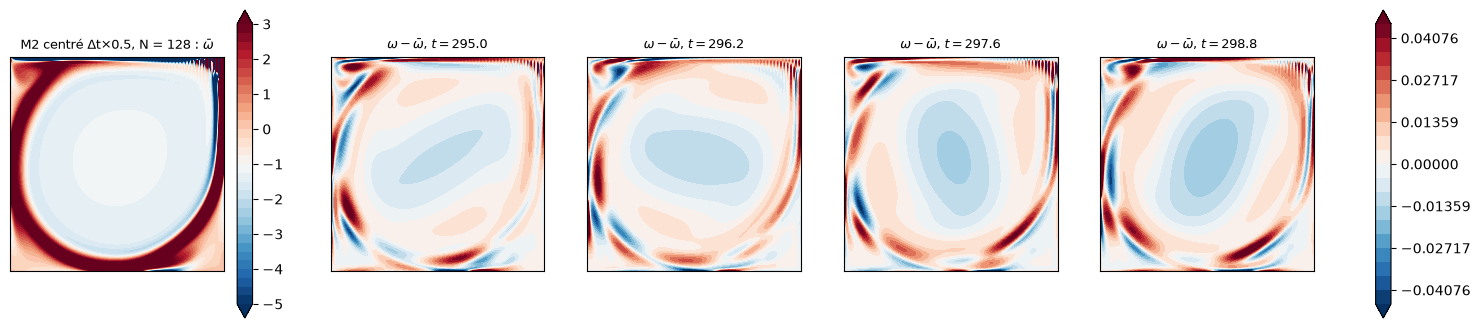

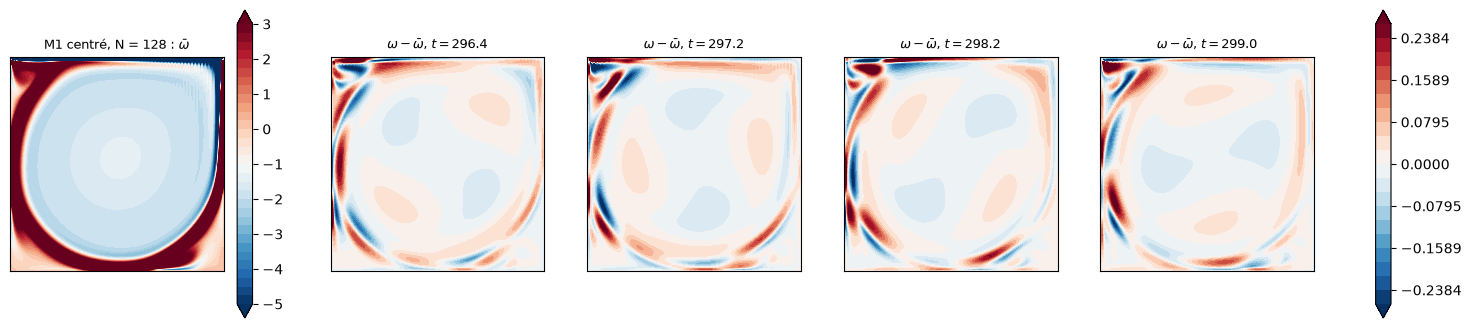

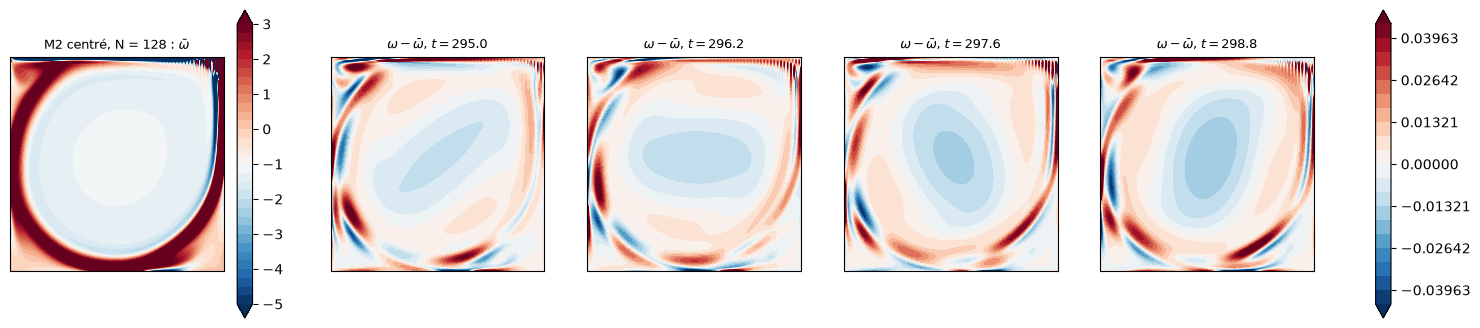

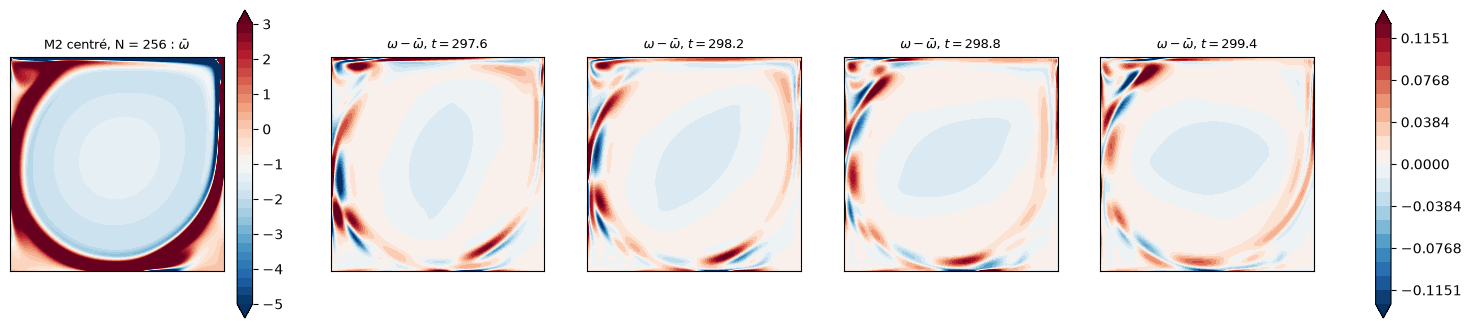

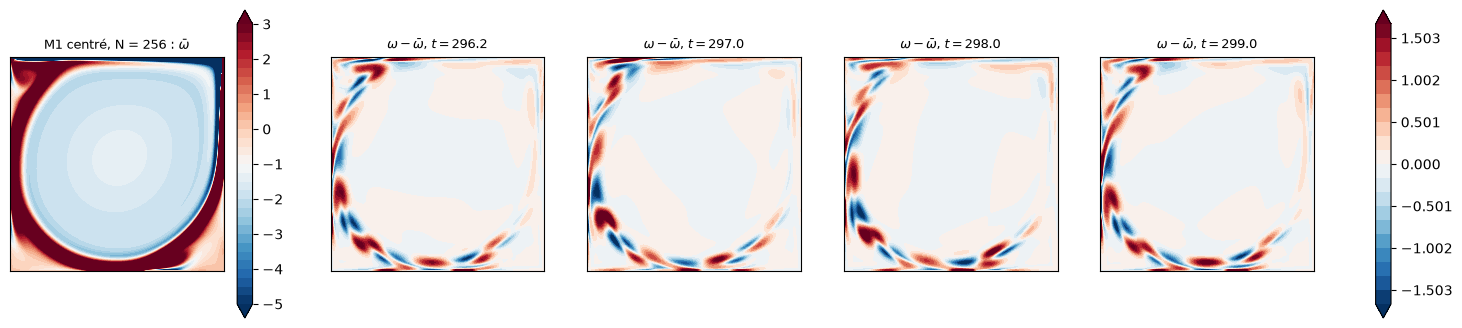

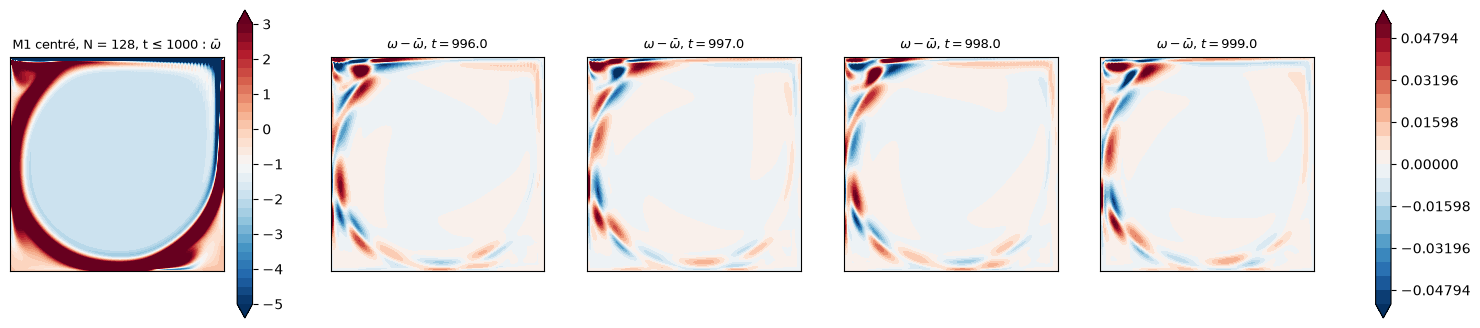

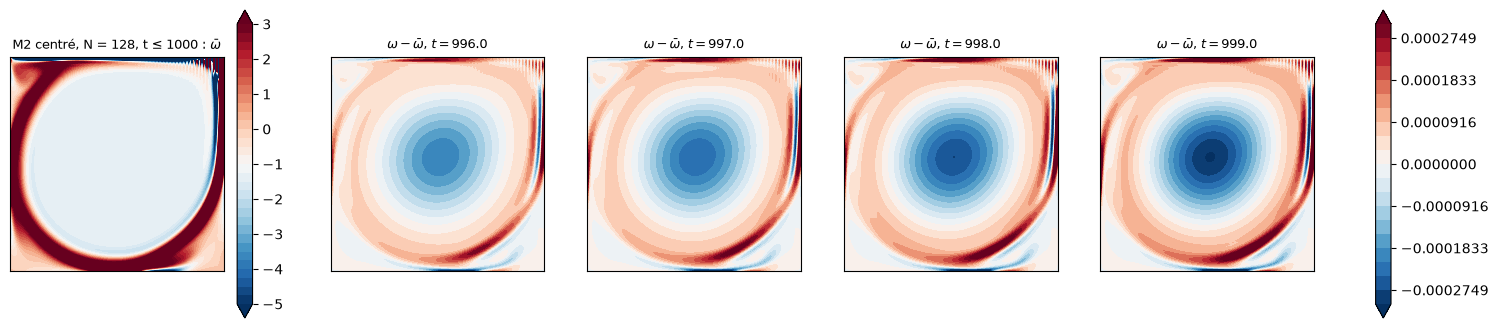

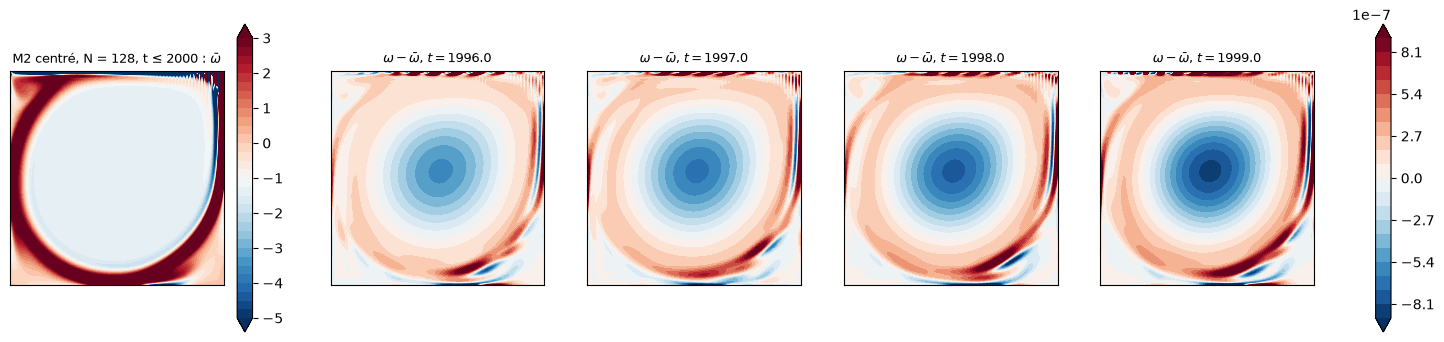

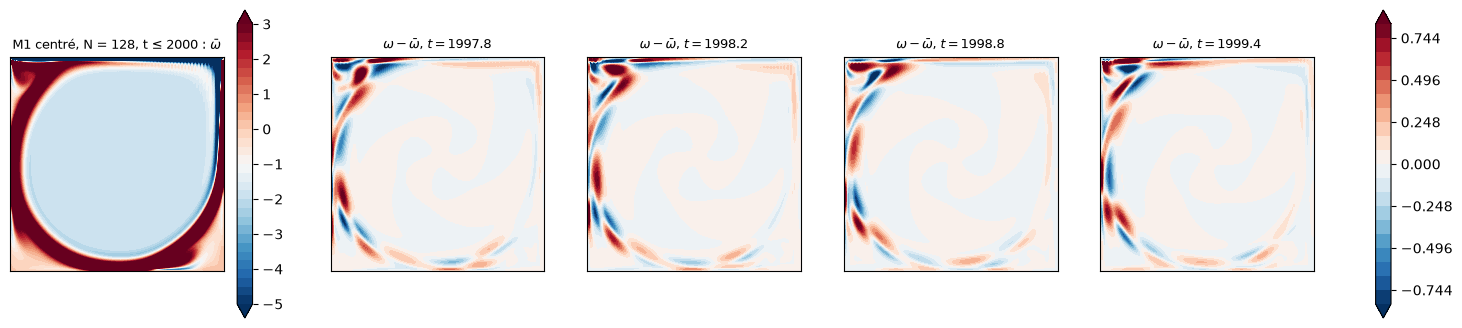

In [9]:
def vorticity(u, v, h):
    # ω = ∂v/∂x − ∂u/∂y, différences centrées d'ordre 2 aux nœuds intérieurs (cours §2.2), 0 aux parois (non tracé)
    w = np.zeros_like(u)
    w[1:-1, 1:-1] = ((v[2:, 1:-1] - v[:-2, 1:-1]) - (u[1:-1, 2:] - u[1:-1, :-2])) / (2.0 * h)
    return w


def snap_vorticity(r):
    # Vorticité de chaque instantané des 20 dernières unités de temps : (n, N+1, N+1)
    last = r["snap_t"] > r["snap_t"][-1] - 20.0 + 1e-9
    if "snap_omega" in r.files:
        return r["snap_t"][last], r["snap_omega"][last]
    u, v = r["snap_u"][last], r["snap_v"][last]
    return r["snap_t"][last], np.array([vorticity(a, b, float(r["h"])) for a, b in zip(u, v)])


for k in centered:
    r = runs[k]
    ts, ws = snap_vorticity(r)
    w_mean = ws.mean(axis=0)
    period = oscillation(r["t"], r["K"])["period"]
    if not np.isfinite(period):
        period = 4.0                                             # pas de période nette : 4 instants espacés d'une unité
    picks = [np.argmin(np.abs(ts - (ts[-1] - period + q * period / 4))) for q in range(4)]
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    im = axes[0].contourf(r["x"], r["y"], w_mean.T, levels=np.linspace(-5, 3, 33), cmap="RdBu_r", extend="both")
    axes[0].set_title(f"{case_name(k)} : $\\bar\\omega$", fontsize=9); fig.colorbar(im, ax=axes[0])
    fluct = ws[picks] - w_mean
    vmax = np.percentile(np.abs(fluct[:, 4:-4, 4:-4]), 99.5)      # bornes sans les 4 rangées de bord (pics aux coins)
    for ax, i, f in zip(axes[1:], picks, fluct):
        im = ax.contourf(r["x"], r["y"], f.T, levels=np.linspace(-vmax, vmax, 21), cmap="RdBu_r", extend="both")
        ax.set_title(f"$\\omega - \\bar\\omega$, $t = {ts[i]:.1f}$", fontsize=9)
    fig.colorbar(im, ax=axes[1:].tolist())
    for ax in axes:
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    fig.savefig(FIG / f"C_vorticity_cycle_case{k}.png", dpi=150)
    plt.show()

**Lecture** (provisoire).
- $\bar\omega$ : tourbillon principal à cœur de vorticité presque uniforme, entouré d'une fine couche de cisaillement ; stries près du coin haut droit (les
  zigzags du §4).
- Fluctuation : structures organisées le long des parois, qui font le tour de la cavité avec la couche de cisaillement, plus des structures lisses au centre.
  Amplitude $\approx 0.24$ pour M1, $\approx 0.04$ pour M2.
- **M1, $N = 256$ (cas 6)** : fluctuation de $\pm 1.5$, en paquets d'ondes le long des parois gauche et du bas, partant du coin haut gauche. Les 4 instants
  sont espacés d'une unité de temps (pas de période nette sur $K$), pas d'un quart de période.
- **M1, $t = 1000$ (cas 7)** : structures de même forme et aux mêmes endroits (coin haut gauche, paroi gauche), d'amplitude $\pm 0.05$ (le mode croît encore).
- **M2, $t = 1000$ (cas 8)** : seulement une lente évolution de la vorticité du cœur ($\pm 3 \cdot 10^{-4}$), pas d'onde : écoulement stationnaire.
- **M2, $N = 256$ (cas 5)** : fluctuation de $\pm 0.12$, de même forme et aux mêmes endroits que M1 à $N = 256$ (paquets le long des parois gauche et du bas,
  coin haut gauche). À $N = 256$, les deux méthodes voient donc le même type d'instabilité, d'intensité différente à $t = 300$.
- **M1, $t = 2000$ (cas 10, cycle limite)** : fluctuation de $\pm 0.74$ ; paquets le long de la paroi gauche et au coin haut gauche, prolongés par des bras
  en spirale vers le cœur. Les 4 instants sont espacés d'un quart de période ($T = 2.283$) : la structure se déplace le long de la paroi.


## 6. Sensibilité aux choix numériques

**Ce qu'on fait.** Un tableau par cas : régime, période et amplitude (sur $K$ et sur la sonde la plus agitée), $K$ et $P$ moyens sur les 50 dernières unités de
temps. Pour l'upwind : diffusion numérique de l'équation modifiée (cours §5.4.2.1) $D = \tfrac12 U h (1 - C)$, $C = U\Delta t/h$, et le Reynolds
« effectif » $Re_\text{eff} = UL/(\nu + D)$ que voit le schéma.

**Ce qu'on attend.** Upwind : $D \gg \nu$, donc $Re_\text{eff}$ bien en dessous de $Re_c$ et un écoulement stationnaire. Centré : M1 et M2, $N = 128$ et $256$,
$\Delta t$ et $\Delta t/2$ doivent donner la même période si l'oscillation est physique et résolue.

In [10]:
print(f"{'cas':<26} | {'régime (K)':<20} | {'T (K)':>6} | {'ampl. rel. K':>12} | {'sonde la plus agitée':<22} | {'T':>6} | "
      f"{'ampl.':>8} | {'K moyen':>9} | {'P moyen':>9}")
for k, r in runs.items():
    t = r["t"]; m = t >= t[-1] - 50
    oK = oscillation(t, r["K"])
    probes = {name: oscillation(t, r["probe_u"][:, j]) for j, name in enumerate(r["probe_names"])}
    best = max(probes, key=lambda p: probes[p]["amplitude"])
    oP = probes[best]
    print(f"{case_name(k):<26} | {regime(oK):<20} | {oK['period']:6.3f} | {oK['rel_amp']:12.1e} | {best:<22} | "
          f"{oP['period']:6.3f} | {oP['amplitude']:8.1e} | {r['K'][m].mean():9.3e} | {r['P'][m].mean():9.3e}")

print("\nUpwind : diffusion numérique (équation modifiée, cours §5.4.2.1), U = 1")
for k, r in runs.items():
    if CASES[k][1] != "upwind":
        continue
    h, dt = float(r["h"]), float(r["dt"])
    c = dt / h
    d_num = 0.5 * h * (1.0 - c)
    print(f"{case_name(k):<26} : C = {c:.2f}, D = {d_num:.2e}, D/ν = {d_num / NU:.0f}, Re_eff = 1/(ν + D) = {1 / (NU + d_num):.0f}")

cas                        | régime (K)           |  T (K) | ampl. rel. K | sonde la plus agitée   |      T |    ampl. |   K moyen |   P moyen


M2 centré Δt×0.5, N = 128  | amortie              |  4.972 |      3.4e-05 | bas_gauche             |  4.970 |  4.5e-04 | 2.302e-02 | 9.483e-03


M1 centré, N = 128         | amortie              |  3.642 |      9.5e-05 | coin_couvercle_gauche  |  3.643 |  7.6e-03 | 4.291e-02 | 8.309e-03


M2 centré, N = 128         | amortie              |  4.974 |      3.3e-05 | bas_gauche             |  4.971 |  4.3e-04 | 2.300e-02 | 9.483e-03
M1 upwind, N = 128         | stationnaire / pas d'oscillation |    nan |      0.0e+00 | centre                 |    nan |  5.1e-07 | 1.960e-02 | 7.757e-03
M2 upwind, N = 128         | stationnaire / pas d'oscillation |    nan |      0.0e+00 | centre                 |    nan |  6.9e-07 | 5.930e-03 | 7.390e-03


M2 centré, N = 256         | amortie              |  2.353 |      5.0e-05 | bas_gauche             |  2.318 |  8.6e-04 | 3.561e-02 | 1.009e-02


M1 centré, N = 256         | amortie              |  3.884 |      3.7e-05 | bas_gauche             |  1.456 |  2.4e-02 | 4.114e-02 | 9.438e-03


M1 centré, N = 128, t ≤ 1000 | stationnaire / pas d'oscillation |    nan |      0.0e+00 | coin_couvercle_gauche  |  2.284 |  1.3e-03 | 4.791e-02 | 8.317e-03


M2 centré, N = 128, t ≤ 1000 | stationnaire / pas d'oscillation |    nan |      0.0e+00 | bas_droit              |  0.034 |  1.1e-09 | 2.586e-02 | 9.483e-03


M2 centré, N = 128, t ≤ 2000 | stationnaire / pas d'oscillation |    nan |      0.0e+00 | coin_couvercle_gauche  |    nan |  0.0e+00 | 2.591e-02 | 9.483e-03


M1 centré, N = 128, t ≤ 2000 | périodique établi    |  2.283 |      6.1e-05 | coin_couvercle_gauche  |  2.283 |  1.9e-02 | 4.786e-02 | 8.314e-03

Upwind : diffusion numérique (équation modifiée, cours §5.4.2.1), U = 1
M1 upwind, N = 128         : C = 0.40, D = 2.34e-03, D/ν = 23, Re_eff = 1/(ν + D) = 409
M2 upwind, N = 128         : C = 0.40, D = 2.34e-03, D/ν = 23, Re_eff = 1/(ν + D) = 409


**Lecture.**
- **Upwind (choix « malheureux »)** : $D/\nu = 23$, donc $Re_\text{eff} \approx 410$, bien en dessous de $Re_c \approx 8000$ : le schéma calcule en fait un écoulement à
  bas $Re$, **stationnaire**, comme prévu par l'équation modifiée. Il supprime la physique qu'on cherche (et ses profils sont loin des références, §7).
- **Pas de temps** : M2 à $\Delta t$ et $\Delta t/2$ donnent la même période (4.972 et 4.974), le même $K$ moyen (à 0.1 %) et le même $P$ moyen :
  **le résultat est convergé en $\Delta t$**.
- **Méthode** : la période (3.64 contre 4.97), l'amplitude (5 à 10 fois plus grande pour M1) et $K$ (facteur 2) dépendent de la méthode. À $N = 128$, les résultats
  sont donc très sensibles à la discrétisation en espace, pas au pas de temps.
- **Durée** : à $t = 300$, M1 et M2 donnaient tous deux une oscillation amortie ; à $t = 1000$, M2 est stationnaire et M1 a une nouvelle oscillation qui croît.
  **La conclusion dépend de $t_\text{max}$** : il faut aller au-delà de $t = 300$ à $Re = 10\,000$.
- **Maillage** (M1) : de $N = 128$ à $256$, la période passe de 3.64 à ~1.46 aux sondes et l'amplitude est multipliée par 14 à la sonde bas gauche (divisée par 2 au coin du couvercle) ; $K(300)$ change de 4 %,
  $P(300)$ de 14 % (effet attendu des coins). L'oscillation n'est **pas convergée en maillage** à $N = 256$, $t = 300$.
- **Maillage** (M2) : de $N = 128$ à $256$, la période passe de 4.97 à ~2.1, $K(300)$ de $2.34$ à $3.63 \cdot 10^{-2}$ (+55 %). **M1 et M2 se rapprochent quand $N$
  augmente** (écart sur $K$ : 46 % puis 13 %), sans encore coïncider.
- **Durée, suite** : à $t = 2000$, M2 ($N = 128$) est stationnaire et M1 ($N = 128$) a atteint un cycle limite de période 2.283. Pour M1, il a fallu
  $t \approx 1450$ pour l'atteindre : **à $Re = 10\,000$ et en partant du repos, le régime établi n'apparaît qu'après plus de 1000 unités de temps.**


## 7. Comparaison à la littérature

**Ce qu'on fait.** Profils $u(0.5, y)$ et $v(x, 0.5)$ **moyennés sur les instantanés des 20 dernières unités de temps**, comparés à Ghia et al. (1982, grille
257²) et Erturk et al. (2005, grille 601²) à $Re = 10\,000$. Attention : ces deux références sont des solutions **stationnaires** (calculs sans pas de temps
physique) ; au-delà de $Re_c$ ce sont des solutions stationnaires instables, que la moyenne temporelle ne reproduit pas forcément. Écart maximal le long de
chaque ligne, notre profil étant interpolé aux points de la référence (parois exclues ; coquille connue de Ghia à $y = 0.5$ ignorée, `ref_data/README.md`).

**Ce qu'on attend.** Un accord de l'ordre de $10^{-2}$ à $N = 256$, moins bon à $N = 128$ (la couche limite sous le couvercle, d'épaisseur
$\sim Re^{-1/2} = 0.01$, ne tient que sur 1.3 maille à $N = 128$).

cas                        | max|Δu| Ghia max|Δv| Ghia | max|Δu| Erturk max|Δv| Erturk
M2 centré Δt×0.5, N = 128  |        0.144        0.159 |          0.156          0.198
M1 centré, N = 128         |        0.039        0.038 |          0.027          0.104
M2 centré, N = 128         |        0.144        0.159 |          0.156          0.199
M2 centré, N = 256         |        0.059        0.060 |          0.053          0.053


M1 centré, N = 256         |        0.044        0.040 |          0.033          0.029


M1 centré, N = 128, t ≤ 1000 |        0.029        0.035 |          0.018          0.112
M2 centré, N = 128, t ≤ 1000 |        0.134        0.150 |          0.152          0.189
M2 centré, N = 128, t ≤ 2000 |        0.134        0.150 |          0.152          0.189
M1 centré, N = 128, t ≤ 2000 |        0.028        0.034 |          0.018          0.112


M1 upwind, N = 128         |        0.224        0.232 |          0.237          0.255
M2 upwind, N = 128         |        0.591        0.543 |          0.598          0.571


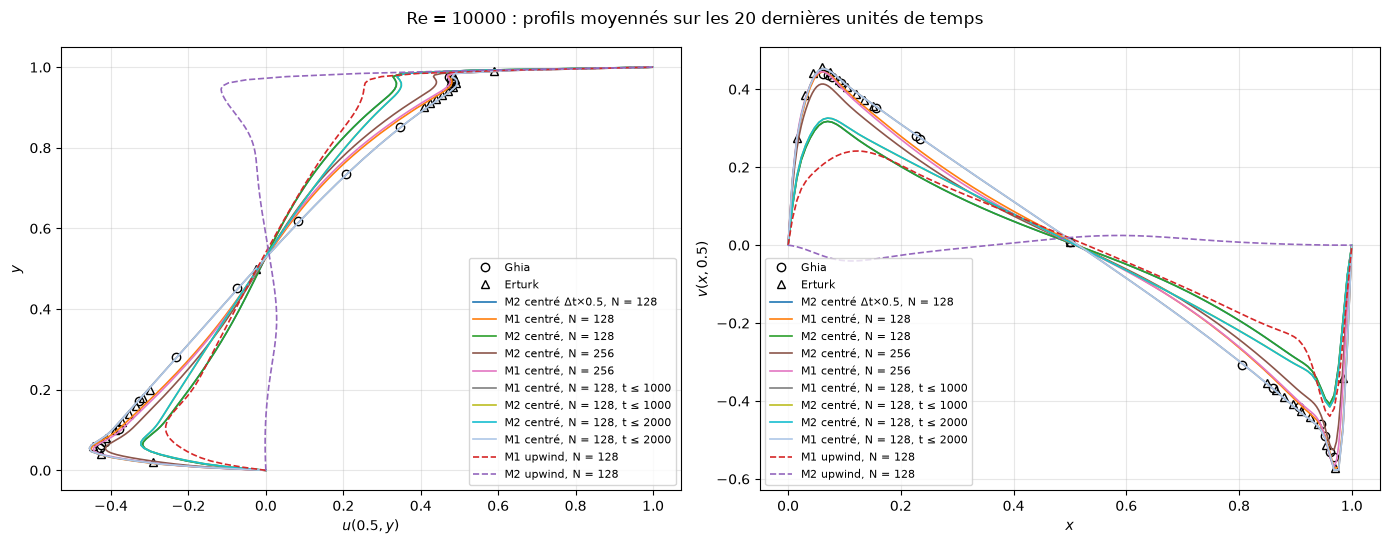

In [11]:
ghia_u = np.loadtxt(REF / "ghia1982_u_vertical_centerline.csv", delimiter=",")
ghia_v = np.loadtxt(REF / "ghia1982_v_horizontal_centerline.csv", delimiter=",")
erturk_u = np.loadtxt(REF / "erturk2005_u_vertical_centerline.csv", delimiter=",")
erturk_v = np.loadtxt(REF / "erturk2005_v_horizontal_centerline.csv", delimiter=",")
COL = {"Ghia": 7, "Erturk": 5}                       # colonne Re = 10 000 (en-têtes des CSV)
REFS = {"Ghia": (ghia_u, ghia_v), "Erturk": (erturk_u, erturk_v)}


def reference(source):
    # Points intérieurs (y, u) et (x, v) ; parois exclues ; coquille de Ghia (u = +0.03111 en y = 0.5, Re = 10 000) ignorée
    tab_u, tab_v = REFS[source]
    yu, u, xv, v = tab_u[:, 0], tab_u[:, COL[source]], tab_v[:, 0], tab_v[:, COL[source]]
    ok_u = (yu > 0) & (yu < 1) & ~((source == "Ghia") & (np.round(yu, 4) == 0.5))
    ok_v = (xv > 0) & (xv < 1)
    return yu[ok_u], u[ok_u], xv[ok_v], v[ok_v]


def mean_profiles(r):
    # u(0.5, y) et v(x, 0.5) moyennés sur les instantanés des 20 dernières unités de temps
    last = r["snap_t"] > r["snap_t"][-1] - 20.0 + 1e-9
    mid = int(r["N"]) // 2
    return r["snap_u"][last][:, mid, :].mean(axis=0), r["snap_v"][last][:, :, mid].mean(axis=0)


fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for src, mk in (("Ghia", "ko"), ("Erturk", "k^")):
    yu, u, xv, v = reference(src)
    axes[0].plot(u, yu, mk, mfc="none", ms=6, label=src)
    axes[1].plot(xv, v, mk, mfc="none", ms=6, label=src)
print(f"{'cas':<26} | {'max|Δu| Ghia':>12} {'max|Δv| Ghia':>12} | {'max|Δu| Erturk':>14} {'max|Δv| Erturk':>14}")
for k in centered + [k for k in runs if CASES[k][1] == "upwind"]:
    r = runs[k]
    u_m, v_m = mean_profiles(r)
    ls = "-" if CASES[k][1] == "centered" else "--"
    axes[0].plot(u_m, r["y"], ls, color=color_of(k), lw=1.2, label=case_name(k))
    axes[1].plot(r["x"], v_m, ls, color=color_of(k), lw=1.2, label=case_name(k))
    err = []
    for src in ("Ghia", "Erturk"):
        yu, u, xv, v = reference(src)
        err += [np.abs(np.interp(yu, r["y"], u_m) - u).max(), np.abs(np.interp(xv, r["x"], v_m) - v).max()]
    print(f"{case_name(k):<26} | {err[0]:12.3f} {err[1]:12.3f} | {err[2]:14.3f} {err[3]:14.3f}")
axes[0].set_xlabel("$u(0.5, y)$"); axes[0].set_ylabel("$y$"); axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$v(x, 0.5)$")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"Re = {RE} : profils moyennés sur les 20 dernières unités de temps")
fig.tight_layout()
fig.savefig(FIG / "C_profiles_ghia_erturk.png", dpi=150)
plt.show()

**Lecture.**
- **M1 centré est le plus proche des références** : écart maximal $0.04$ à Ghia et $0.03$ (sur $u$) à $0.10$ (sur $v$, près de la paroi droite) à Erturk.
- **M2 centré s'en écarte nettement** ($0.14$ à $0.20$) : tourbillon principal trop faible, comme en Partie B, où l'erreur de la formule de Thom grandit
  comme $h\sqrt{Re}$ (`Doc/partie_B_limites.md` §3). M2 à $\Delta t/2$ donne les mêmes écarts (à $10^{-3}$ près) : ce n'est pas une erreur de pas de temps.
- **$N = 256$, M1** : l'écart sur $v$ à Erturk passe de $0.10$ à $0.03$ ; sur $u$, $0.03$–$0.04$ comme à $N = 128$.
- **$N = 256$, M2** : écarts $0.05$–$0.06$, contre $0.14$–$0.20$ à $N = 128$ : divisés par 2.4 à 3.8 quand $h$ est divisé par 2. L'erreur de M2 à $N = 128$ était donc
  bien une erreur de discrétisation (Thom), qui diminue avec $h$.
- **$t = 1000$** : M1 se rapproche un peu des références ($0.03$ à Ghia, $0.02$ sur $u$ à Erturk ; $v$ reste à $0.11$ à Erturk). **M2, pourtant stationnaire,
  reste loin** ($0.13$ à $0.19$) : son état stationnaire n'est pas celui des références ; c'est une erreur de discrétisation (Thom, Partie B), pas un
  écoulement inachevé.
- **Upwind** : très loin ($0.22$–$0.26$ pour M1, $0.54$–$0.60$ pour M2, dont le cœur est presque au repos ; cause non encore isolée).

**$Re_c$ et période dans la littérature.** $Re_c \approx 7400$–$8050$ selon la méthode et le maillage (`ref_data/README.md`) ; Erturk et al. trouvent un calcul
périodique à $Re = 7500$ sur 129² mais stationnaire sur 257² : sur grille grossière, une partie de l'instationnarité est numérique. **Période de
référence : à relever dans un article (aucune valeur n'est encore dans `ref_data/`) ; on n'en cite pas sans l'avoir lue.**
- **$t = 2000$** : profils moyens identiques à ceux de $t = 1000$ à $10^{-3}$ près, pour M1 comme pour M2 : l'écoulement moyen ne change plus.


## 8. Bilan

1. **Le pas de temps n'y est pour rien** : M2 à $\Delta t/2$ redonne la même période (4.972 contre 4.974), le même amortissement, le même $K$ et les mêmes
   profils. Les écarts entre M1 et M2 viennent de la discrétisation en espace.
2. **Il faut des temps longs** : l'écoulement moyen n'est établi que vers $t \approx 1000$ et le régime de M1 seulement vers $t \approx 1450$ ; à $t = 300$,
   toutes les oscillations semblaient amorties.
3. **M1, $N = 128$ : régime périodique établi** (cycle limite) de période $T = 2.283$, amplitude constante de $t = 1450$ à $2000$, une seule période pour
   $K$ et les six sondes, fluctuation localisée le long de la paroi gauche et au coin haut gauche.
4. **M2, $N = 128$ : stationnaire** jusqu'à $t = 2000$. À $N = 128$, le régime dépend donc de la méthode : on ne peut pas conclure sur la physique à ce
   maillage. L'erreur de M2 (formule de Thom) est grande à $N = 128$ ($0.13$–$0.19$ d'écart aux références).
5. **À $N = 256$, M1 et M2 se rapprochent** : écart sur $K$ de 13 % (46 % à $N = 128$), écart de M2 aux références divisé par 2.4 à 3.8, même type de
   fluctuation (paroi gauche, bas, coin haut gauche), périodes du même ordre (1.5 et 2.1). Mais ces calculs ne vont que jusqu'à $t = 300$ : régime
   final inconnu à $N = 256$.
6. **Zigzags numériques** sous le couvercle (coin droit) à $N = 128$, plus faibles à $N = 256$, présents même dans l'état stationnaire de M2 : ils ne sont
   pas la source de l'oscillation, qui se trouve ailleurs (paroi gauche).
7. **Upwind** : stationnaire, $Re_\text{eff} \approx 410$, comme le prévoit l'équation modifiée.

**Conclusion.** Nous obtenons un régime périodique établi ($T = 2.283$) avec M1 à $N = 128$ ; mais M2 sur le même maillage est stationnaire, et le
calcul à $N = 256$ montre que la période dépend encore du maillage. Le caractère physique de ce régime n'est donc pas démontré : il faudrait M1 et M2
à $N = 256$ (ou plus) sur $t \gtrsim 1500$, soit plusieurs jours de calcul par cas sur cette machine.
